In [1]:
!pip install tensorflow tensorflow.keras
!pip install numpy
!pip install scipy
!pip install pandas
!pip install matplotlib
!pip install scikit-learn


Coercion summary (new NaNs introduced by coercion):
  shallow_depth_s: +0 NaNs
  Deep_depth_s: +0 NaNs
  river_discharge: +0 NaNs
  Deep_depth_t: +0 NaNs
  chlorophyll_depth: +0 NaNs
Examples of original values coerced to NaN (up to 5 examples per column):
  shallow_depth_s: []
  Deep_depth_s: []
  river_discharge: []
  Deep_depth_t: []
  chlorophyll_depth: []
Dropped 27 rows with NaNs in required columns (remaining 575 rows).
Saved dropped rows to 'dropped_rows_inspection.csv' (first 5 rows):
     shallow_depth_s  Deep_depth_s  river_discharge  Deep_depth_t  \
170            0.100           NaN           4600.0         3.463   
520            0.992         2.373              NaN         9.656   
521            0.185         8.361              NaN        10.767   
522            0.031         7.100              NaN         7.011   
523            0.030        11.426              NaN         0.662   

     chlorophyll_depth       drop_reasons  
170              0.724     [Deep_depth_s] 

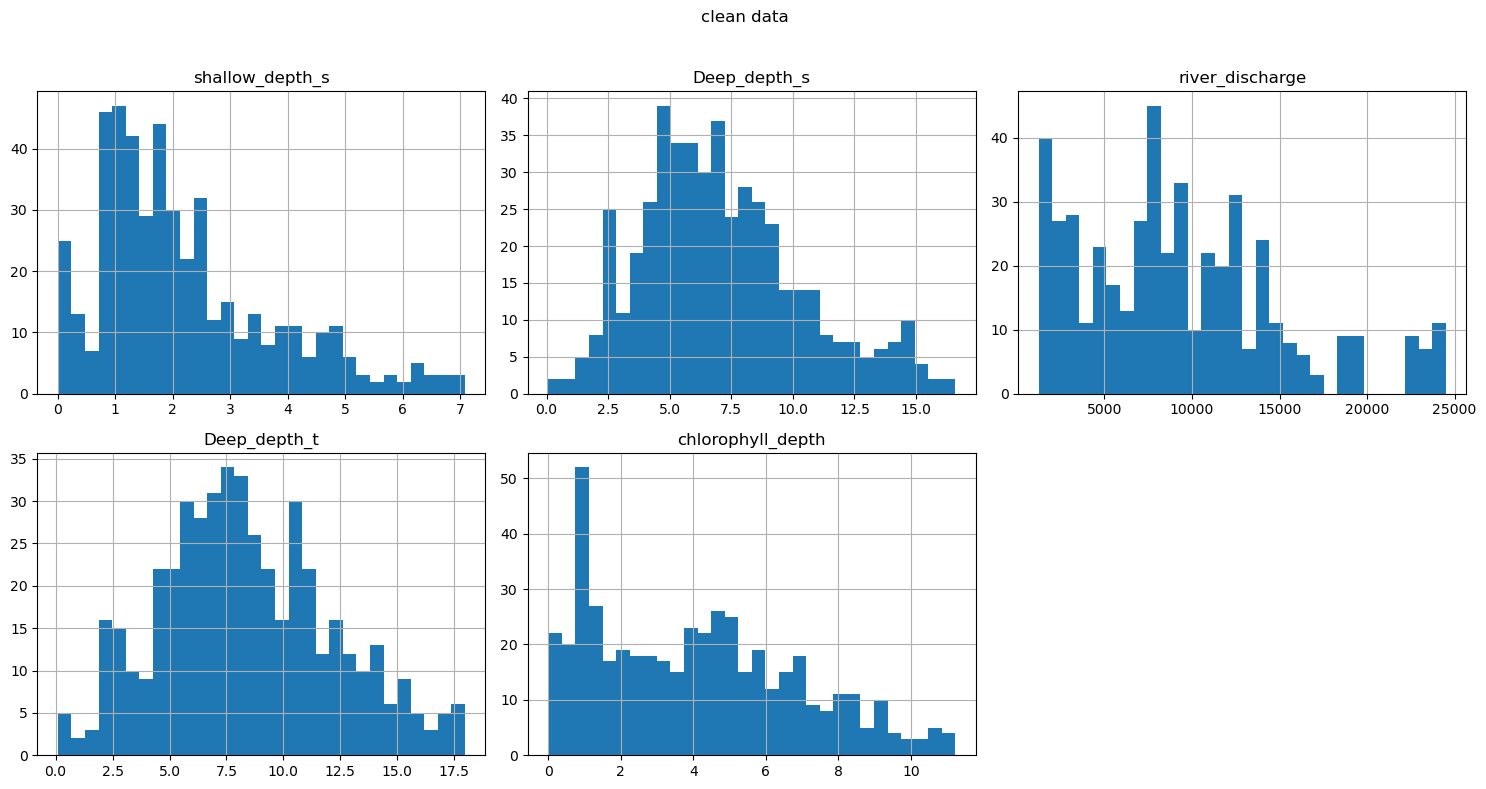

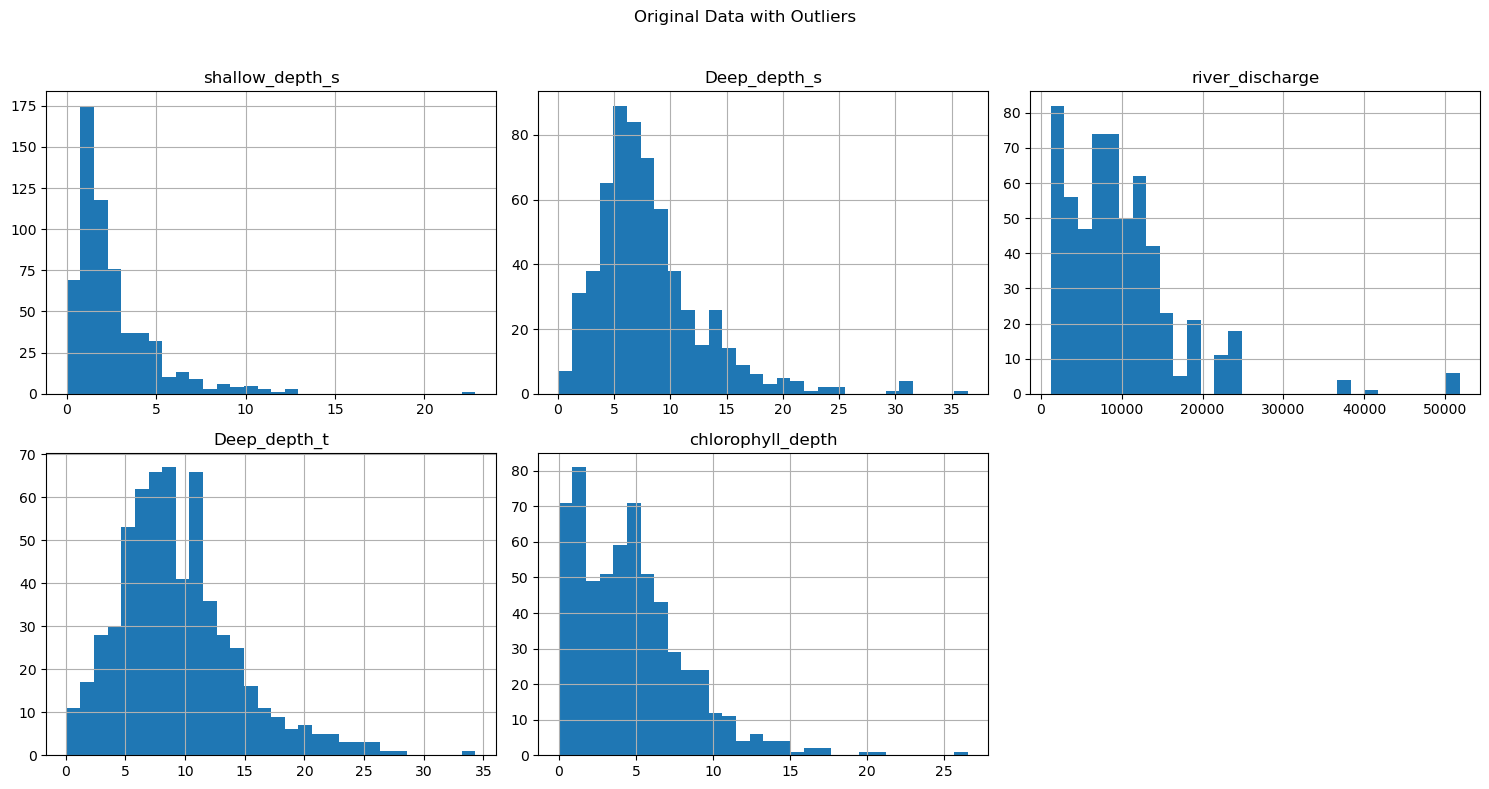

In [1]:

# 2. Load and Prepare Your Data
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

# Load data
data = pd.read_csv('Raw data chlorocline.csv', encoding='latin-1') # Try 'latin-1' encoding

# Feature and target columns (ensure these match your CSV headers)
feature_cols = ['shallow_depth_s', 'Deep_depth_s','river_discharge', 'Deep_depth_t']
target_col = 'chlorophyll_depth'


def remove_outliers(df):
    """
    Removes rows containing outliers in the specified columns using the Z-score method.
    """
    df_cleaned = df.copy()
    cols_to_check = feature_cols + [target_col]
    present_cols = [c for c in cols_to_check if c in df_cleaned.columns]
    missing_cols = [c for c in cols_to_check if c not in df_cleaned.columns]
    if missing_cols:
        print(f"Warning: Column(s) not found in the DataFrame and will be skipped: {missing_cols}")

    # Ensure we don't try to z-score constant or empty columns
    for col in present_cols:
        # coerce object columns to numeric where possible
        if df_cleaned[col].dtype == object:
            df_cleaned[col] = pd.to_numeric(df_cleaned[col], errors='coerce')
        if df_cleaned[col].dropna().nunique() <= 1:
            continue
        # compute zscore safely
        try:
            z = stats.zscore(df_cleaned[col].astype(float))
        except Exception:
            continue
        outlier_mask = np.abs(z) > 2  # adjust threshold if desired
        df_cleaned = df_cleaned[~outlier_mask]

    return df_cleaned


def coerce_and_clean_numeric(df, cols, target_col):
    """Coerce listed columns to numeric, replace infs, drop rows with NaNs, and provide diagnostics.

    Returns the cleaned DataFrame (rows kept). Also saves dropped rows to 'dropped_rows_inspection.csv'.
    """
    df2 = df.copy()
    converted = {}
    coercion_examples = {}

    for c in cols + [target_col]:
        if c in df2.columns:
            before_na = df2[c].isna().sum()
            # attempt coercion and capture examples of values that fail
            coerced = pd.to_numeric(df2[c], errors='coerce')
            coerced_mask = df2[c].notna() & coerced.isna()
            coercion_examples[c] = df2.loc[coerced_mask, c].head(5).tolist()
            df2[c] = coerced
            after_na = df2[c].isna().sum()
            converted[c] = after_na - before_na

    # Replace inf values with NaN
    df2 = df2.replace([np.inf, -np.inf], np.nan)

    print("Coercion summary (new NaNs introduced by coercion):")
    for k, v in converted.items():
        print(f"  {k}: +{v} NaNs")

    print("Examples of original values coerced to NaN (up to 5 examples per column):")
    for k, v in coercion_examples.items():
        print(f"  {k}: {v}")

    present_cols = [c for c in cols + [target_col] if c in df2.columns]
    before = df2.shape[0]

    # identify rows that will be dropped and keep a copy for diagnostics
    dropped_rows = df2[df2[present_cols].isnull().any(axis=1)].copy() if present_cols else df2.iloc[0:0].copy()
    df2_kept = df2.dropna(subset=present_cols) if present_cols else df2.copy()
    after = df2_kept.shape[0]

    print(f"Dropped {before - after} rows with NaNs in required columns (remaining {after} rows).")

    if not dropped_rows.empty:
        # summarize drop reasons per-row
        def reasons(row):
            return [col for col in present_cols if pd.isna(row[col])]
        dropped_rows['drop_reasons'] = dropped_rows.apply(reasons, axis=1)
        # save dropped rows for inspection
        try:
            dropped_rows.to_csv('dropped_rows_inspection.csv', index=False)
            print("Saved dropped rows to 'dropped_rows_inspection.csv' (first 5 rows):")
        except Exception as e:
            print("Failed to save dropped_rows_inspection.csv:", e)
        display_cols = [c for c in present_cols if c in dropped_rows.columns]
        print(dropped_rows.head()[display_cols + ['drop_reasons']])

    return df2_kept


# Apply cleaning and outlier removal
if 'data' in locals():
    data_numeric = coerce_and_clean_numeric(data, feature_cols, target_col)
    data_cleaned = remove_outliers(data_numeric)
    # Save cleaned data for inspection
    try:
        data_cleaned.to_csv('data_cleaned.csv', index=False)
        print("Saved cleaned data to 'data_cleaned.csv'")
    except Exception as e:
        print("Failed to save data_cleaned.csv:", e)

    print("Original DataFrame shape:", data.shape)
    print("DataFrame shape after coercion+outlier removal:", data_cleaned.shape)
else:
    print("Please load your DataFrame into a variable named 'data' before running this code.")


def plot_histograms(data, feature_cols, target_col, title):
    """
    Plots histograms for the specified feature columns and target column.

    Args:
        data (pd.DataFrame): The input DataFrame.
        feature_cols (list): List of feature column names.
        target_col (str): The target column name.
    """
    columns_to_plot = [c for c in feature_cols + [target_col] if c in data.columns]
    if not columns_to_plot:
        print("No columns available to plot.")
        return
    data[columns_to_plot].hist(bins=30, figsize=(15, 8), layout=(2, 3))
    plt.suptitle(title)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

# If data_cleaned exists, plot histograms
if 'data_cleaned' in locals():
    plot_histograms(data_cleaned, feature_cols, target_col, 'clean data')
if 'data' in locals():
    plot_histograms(data, feature_cols, target_col, "Original Data with Outliers")


2025-09-30 14:05:55.063922: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1759266355.081143 1157531 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1759266355.086605 1157531 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-09-30 14:05:55.104685: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Epoch 1/10


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2025-09-30 14:05:56.442316: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_UNKNOWN: unknown error
2025-09-30 14:05:56.442340: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:137] retrieving CUDA diagnostic information for host: llenoyann
2025-09-30 14:05:56.442346: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:144] hostname: llenoyann
2025-09-30 14:05:56.442509: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:168] libcuda reported version is: 550.163.1
2025-09-30 14:05:56.442545: I external/local_

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 15.9294 - val_loss: 9.2438
Epoch 2/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8325 - val_loss: 8.8498
Epoch 3/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6817 - val_loss: 8.9169
Epoch 4/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7760 - val_loss: 9.0313
Epoch 5/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7698 - val_loss: 8.9201
Epoch 6/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 6.9552 - val_loss: 9.1675
Epoch 7/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3523 - val_loss: 8.8400
Epoch 8/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.3525 - val_loss: 8.9714
Epoch 9/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9942 - val_loss: 8.8419
Epoch 10/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5397 - val_loss: 9.0299
tanh_adam_10=>Activation: tanh, Optimizer: adam, Epochs: 10, Test MSE: 6.196041107177734


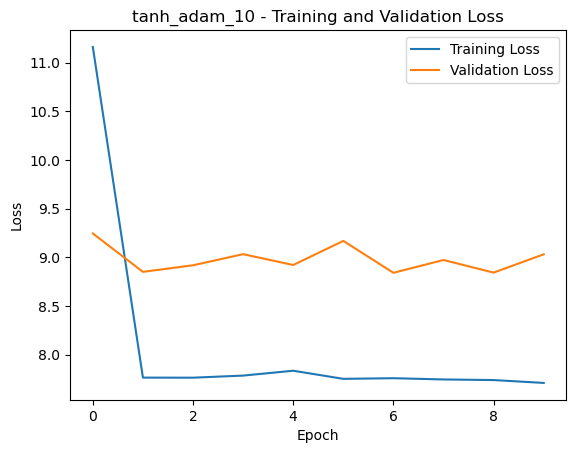

Epoch 1/25


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 13.3692 - val_loss: 8.8919
Epoch 2/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.9550 - val_loss: 8.8135
Epoch 3/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 6.9336 - val_loss: 9.0818
Epoch 4/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6409 - val_loss: 8.9776
Epoch 5/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.1684 - val_loss: 8.8873
Epoch 6/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7756 - val_loss: 8.8441
Epoch 7/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7755 - val_loss: 9.0283
Epoch 8/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 6.9510 - val_loss: 8.8189
Epoch 9/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.2657 - val_loss: 8.9066
Epoch 10/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.2968 - val_loss: 8.9390
Epoch 11/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9330 - val_loss: 8.9010
Epoch 12/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4495 - val_loss: 8.929

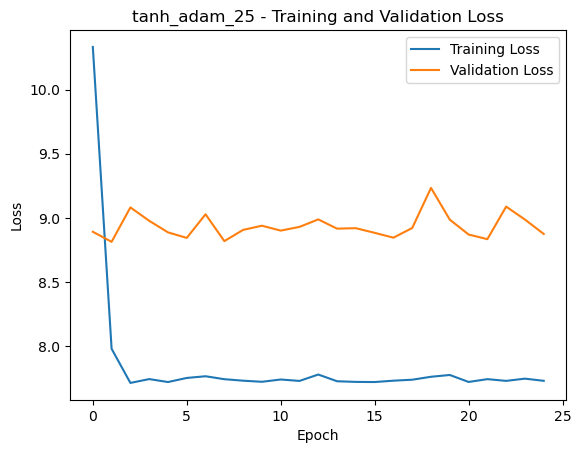

Epoch 1/50


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 14.2563 - val_loss: 9.0332
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8524 - val_loss: 8.7932
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7272 - val_loss: 9.1694
Epoch 4/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6479 - val_loss: 8.9604
Epoch 5/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6169 - val_loss: 8.8068
Epoch 6/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7363 - val_loss: 8.9463
Epoch 7/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4583 - val_loss: 8.9088
Epoch 8/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4148 - val_loss: 8.8528
Epoch 9/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3474 - val_loss: 8.9302
Epoch 10/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7838 - val_loss: 9.0359
Epoch 11/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9022 - val_loss: 8.8890
Epoch 12/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0796 - val_loss: 8.871

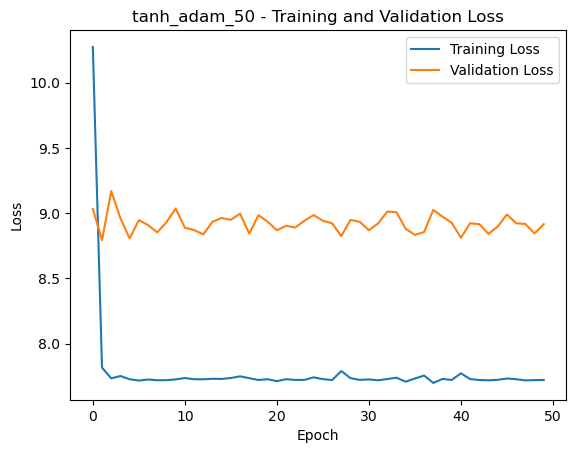

Epoch 1/100


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 14.3831 - val_loss: 8.7419
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.5590 - val_loss: 9.0858
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.1939 - val_loss: 9.0315
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9509 - val_loss: 8.7927
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6717 - val_loss: 8.9732
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4595 - val_loss: 9.1549
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6369 - val_loss: 8.9223
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3507 - val_loss: 8.9449
Epoch 9/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8059 - val_loss: 8.8739
Epoch 10/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3429 - val_loss: 8.8628
Epoch 11/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4339 - val_loss: 8.9098
Epoch 12/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7305 - val_

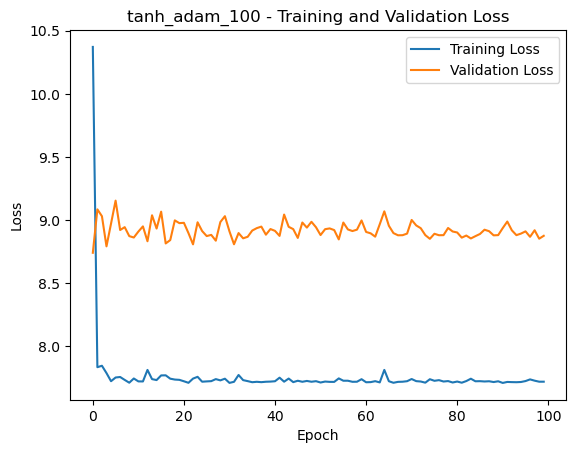

Epoch 1/500


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 12.8870 - val_loss: 8.8128
Epoch 2/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7151 - val_loss: 8.9403
Epoch 3/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6597 - val_loss: 8.9680
Epoch 4/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5256 - val_loss: 8.8739
Epoch 5/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 6.8150 - val_loss: 8.9383
Epoch 6/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7292 - val_loss: 9.0062
Epoch 7/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5944 - val_loss: 8.9694
Epoch 8/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7240 - val_loss: 8.9664
Epoch 9/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 6.8926 - val_loss: 8.9875
Epoch 10/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9189 - val_loss: 8.8228
Epoch 11/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6533 - val_loss: 8.9619
Epoch 12/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.9686 - val_

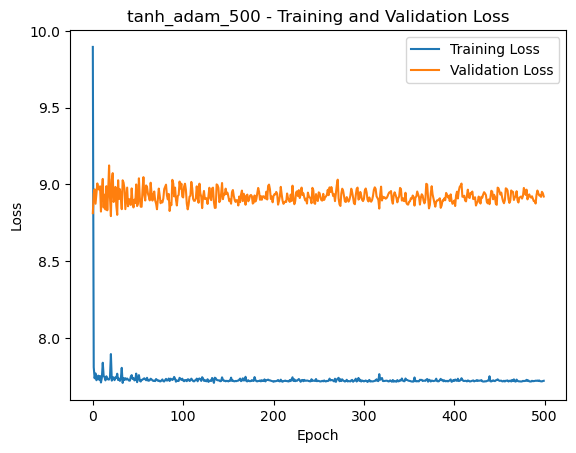

Epoch 1/1000


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 19.1296 - val_loss: 9.1311
Epoch 2/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.2502 - val_loss: 8.7964
Epoch 3/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9003 - val_loss: 9.1331
Epoch 4/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6540 - val_loss: 8.8581
Epoch 5/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6718 - val_loss: 8.9176
Epoch 6/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.1207 - val_loss: 8.9261
Epoch 7/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9610 - val_loss: 8.9016
Epoch 8/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5487 - val_loss: 8.9702
Epoch 9/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.1562 - val_loss: 8.9643
Epoch 10/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 6.8283 - val_loss: 8.9418
Epoch 11/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5092 - val_loss: 9.1986
Epoch 12/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.

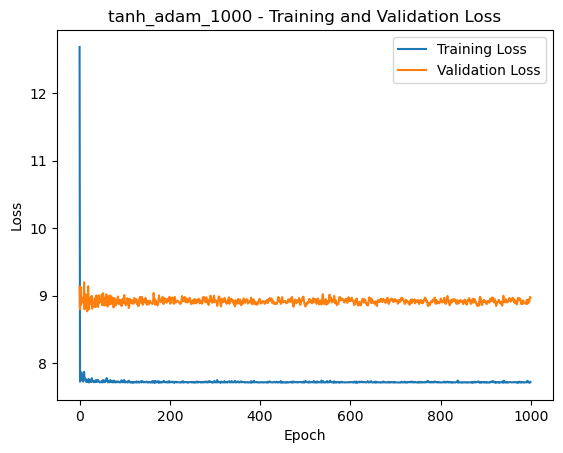

Epoch 1/10


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 13.8920 - val_loss: 8.7503
Epoch 2/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.2044 - val_loss: 8.7322
Epoch 3/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6209 - val_loss: 9.2995
Epoch 4/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.3840 - val_loss: 9.2588
Epoch 5/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3401 - val_loss: 8.7332
Epoch 6/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5349 - val_loss: 8.8892
Epoch 7/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.2062 - val_loss: 9.2440
Epoch 8/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4826 - val_loss: 8.8735
Epoch 9/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.4051 - val_loss: 8.7565
Epoch 10/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6302 - val_loss: 8.8000
tanh_sgd_10=>Activation: tanh, Optimizer: sgd, Epochs: 10, Test MSE: 6.144450664520264


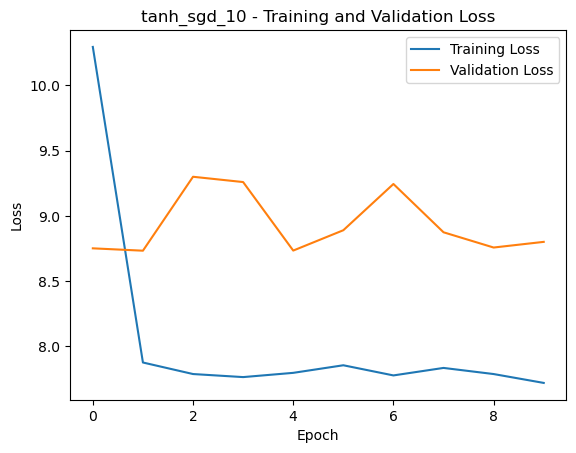

Epoch 1/25


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 11.5620 - val_loss: 9.9022
Epoch 2/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.1485 - val_loss: 8.7674
Epoch 3/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.8686 - val_loss: 10.0316
Epoch 4/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6030 - val_loss: 8.7726
Epoch 5/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.2428 - val_loss: 8.9152
Epoch 6/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.0017 - val_loss: 8.7874
Epoch 7/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.1944 - val_loss: 8.8997
Epoch 8/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4726 - val_loss: 9.9297
Epoch 9/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.1681 - val_loss: 9.8874
Epoch 10/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9751 - val_loss: 8.7454
Epoch 11/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6550 - val_loss: 8.9247
Epoch 12/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6030 - val_loss: 8.78

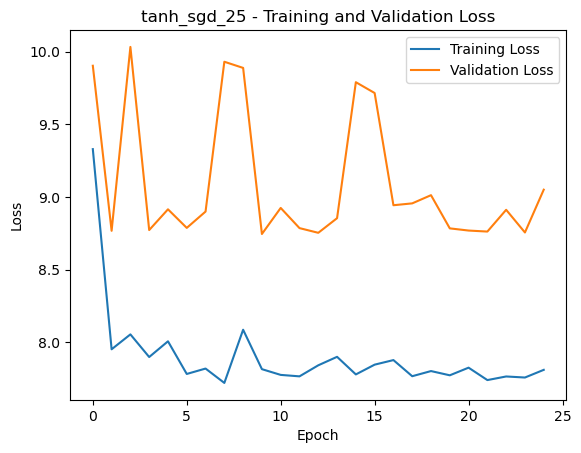

Epoch 1/50


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 10.8950 - val_loss: 9.0117
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5579 - val_loss: 9.1165
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.2488 - val_loss: 10.5000
Epoch 4/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0916 - val_loss: 8.7612
Epoch 5/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.2656 - val_loss: 8.8565
Epoch 6/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3630 - val_loss: 8.8404
Epoch 7/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 7.7551 - val_loss: 9.3747
Epoch 8/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5163 - val_loss: 9.2959
Epoch 9/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0401 - val_loss: 9.4392
Epoch 10/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8756 - val_loss: 9.5513
Epoch 11/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6525 - val_loss: 8.8309
Epoch 12/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.3904 - val_loss: 8.73

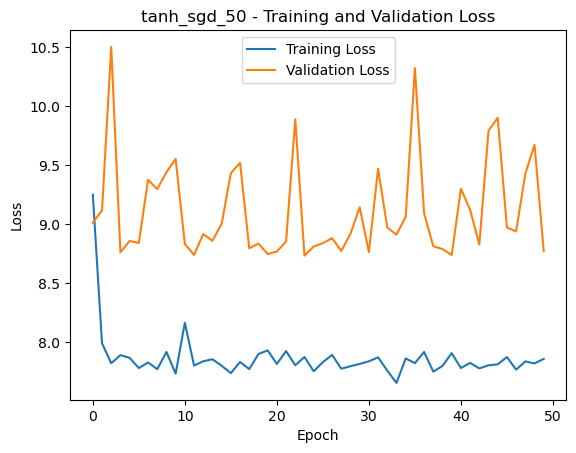

Epoch 1/100


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 9.9348 - val_loss: 9.4181
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.2155 - val_loss: 8.8251
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.2930 - val_loss: 10.2460
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6862 - val_loss: 9.0440
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.2934 - val_loss: 9.1832
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.3028 - val_loss: 8.7392
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.4821 - val_loss: 8.7561
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5015 - val_loss: 9.2220
Epoch 9/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 8.7435 - val_loss: 8.9821
Epoch 10/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9346 - val_loss: 8.8588
Epoch 11/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7004 - val_loss: 8.8102
Epoch 12/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0129 - val_

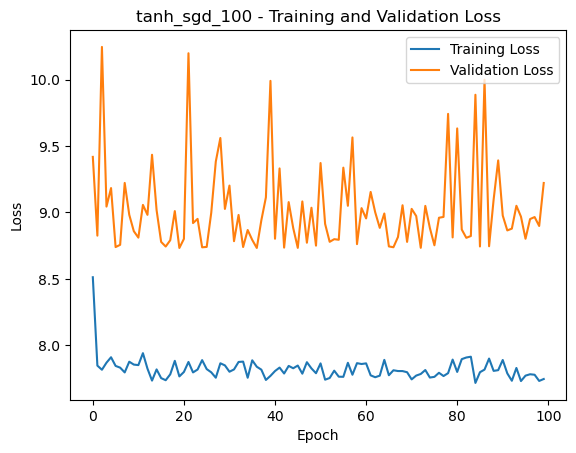

Epoch 1/500


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 13.4234 - val_loss: 8.7927
Epoch 2/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9413 - val_loss: 9.7516
Epoch 3/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8957 - val_loss: 8.7463
Epoch 4/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8540 - val_loss: 9.4349
Epoch 5/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7512 - val_loss: 8.7521
Epoch 6/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9243 - val_loss: 9.3484
Epoch 7/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4374 - val_loss: 8.7603
Epoch 8/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 7.7590 - val_loss: 9.5349
Epoch 9/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5778 - val_loss: 8.7383
Epoch 10/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.3601 - val_loss: 8.7348
Epoch 11/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5263 - val_loss: 10.2489
Epoch 12/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6912 - val

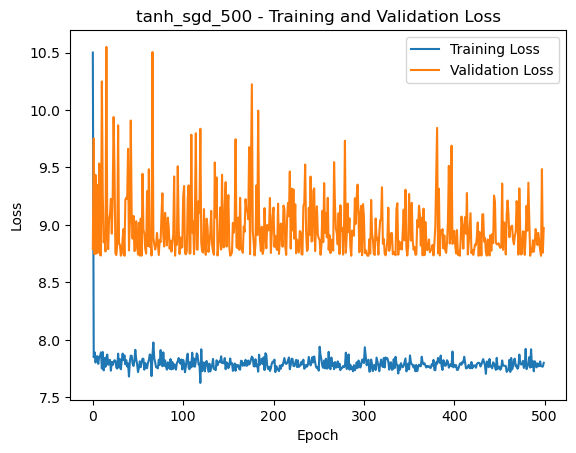

Epoch 1/1000
 1/11 ━━━━━━━━━━━━━━━━━━━━ 1s 156ms/step - loss: 27.0609

/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 13.0357 - val_loss: 8.9066
Epoch 2/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4140 - val_loss: 9.5735
Epoch 3/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.2391 - val_loss: 11.2396
Epoch 4/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.2834 - val_loss: 8.9639
Epoch 5/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7435 - val_loss: 9.0171
Epoch 6/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6021 - val_loss: 8.8534
Epoch 7/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7324 - val_loss: 8.9859
Epoch 8/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9117 - val_loss: 8.8283
Epoch 9/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8054 - val_loss: 8.9972
Epoch 10/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8735 - val_loss: 9.1680
Epoch 11/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6606 - val_loss: 8.7983
Epoch 12/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7

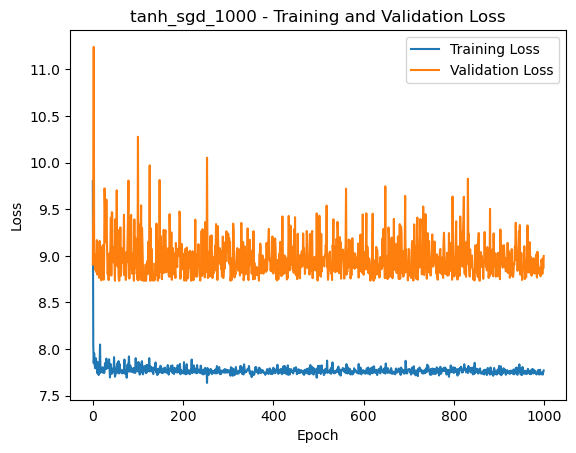

Epoch 1/10


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 11.8241 - val_loss: 8.9254
Epoch 2/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4718 - val_loss: 9.2459
Epoch 3/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8636 - val_loss: 9.2172
Epoch 4/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0927 - val_loss: 8.7525
Epoch 5/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.7375 - val_loss: 9.0103
Epoch 6/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8275 - val_loss: 9.0895
Epoch 7/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5351 - val_loss: 9.1128
Epoch 8/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9909 - val_loss: 8.7389
Epoch 9/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3815 - val_loss: 9.1412
Epoch 10/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6700 - val_loss: 8.7482
tanh_rmsprop_10=>Activation: tanh, Optimizer: rmsprop, Epochs: 10, Test MSE: 6.3345112800598145


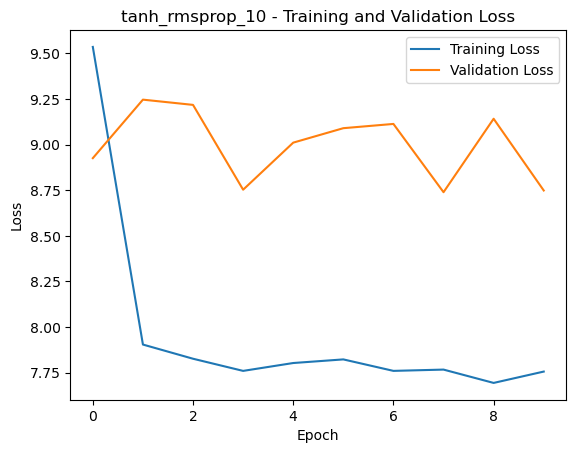

Epoch 1/25


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 15.7378 - val_loss: 8.9566
Epoch 2/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5781 - val_loss: 9.0650
Epoch 3/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8728 - val_loss: 9.0199
Epoch 4/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.4516 - val_loss: 9.2228
Epoch 5/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4295 - val_loss: 8.8252
Epoch 6/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4521 - val_loss: 9.2396
Epoch 7/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8717 - val_loss: 8.9015
Epoch 8/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8235 - val_loss: 8.7322
Epoch 9/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8258 - val_loss: 9.3416
Epoch 10/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.2918 - val_loss: 9.1247
Epoch 11/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9063 - val_loss: 8.7845
Epoch 12/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5906 - val_loss: 8.851

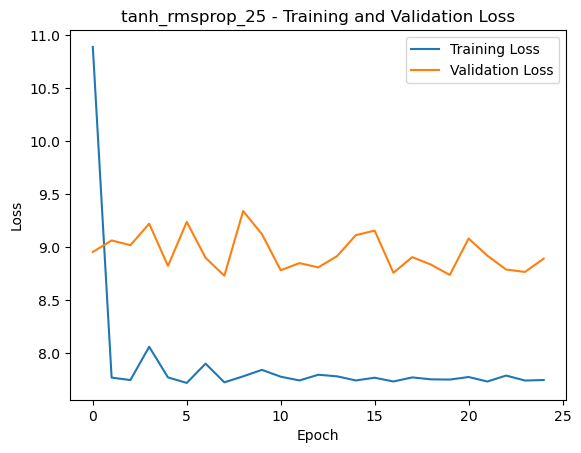

Epoch 1/50


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 14.0178 - val_loss: 9.2037
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3174 - val_loss: 8.9839
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4443 - val_loss: 8.9025
Epoch 4/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9730 - val_loss: 8.7407
Epoch 5/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8108 - val_loss: 9.1873
Epoch 6/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.6149 - val_loss: 8.8702
Epoch 7/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8994 - val_loss: 9.0391
Epoch 8/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 6.8922 - val_loss: 8.9635
Epoch 9/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7313 - val_loss: 8.7322
Epoch 10/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.2928 - val_loss: 9.0557
Epoch 11/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4372 - val_loss: 9.1317
Epoch 12/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4439 - val_loss: 8.962

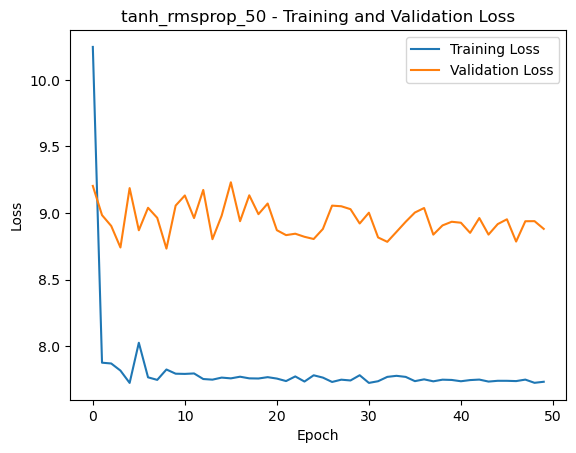

Epoch 1/100


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 11.1343 - val_loss: 9.6262
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.8656 - val_loss: 9.1937
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.4642 - val_loss: 9.1081
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7423 - val_loss: 8.8745
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8073 - val_loss: 9.1351
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9559 - val_loss: 9.1703
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7982 - val_loss: 8.7323
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0878 - val_loss: 8.7333
Epoch 9/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5978 - val_loss: 8.8435
Epoch 10/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.1854 - val_loss: 9.0643
Epoch 11/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9266 - val_loss: 9.1221
Epoch 12/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.2338 - val_

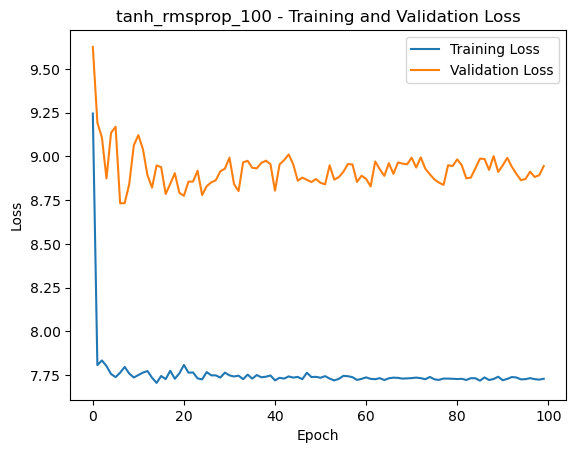

Epoch 1/500


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 12.4713 - val_loss: 8.9410
Epoch 2/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4699 - val_loss: 9.1402
Epoch 3/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6149 - val_loss: 8.7346
Epoch 4/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.0958 - val_loss: 9.1487
Epoch 5/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.3355 - val_loss: 8.9804
Epoch 6/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9019 - val_loss: 9.0496
Epoch 7/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7563 - val_loss: 8.9817
Epoch 8/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9487 - val_loss: 8.9013
Epoch 9/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.1528 - val_loss: 9.1196
Epoch 10/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8782 - val_loss: 8.9092
Epoch 11/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8528 - val_loss: 8.9147
Epoch 12/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.8236 - val_

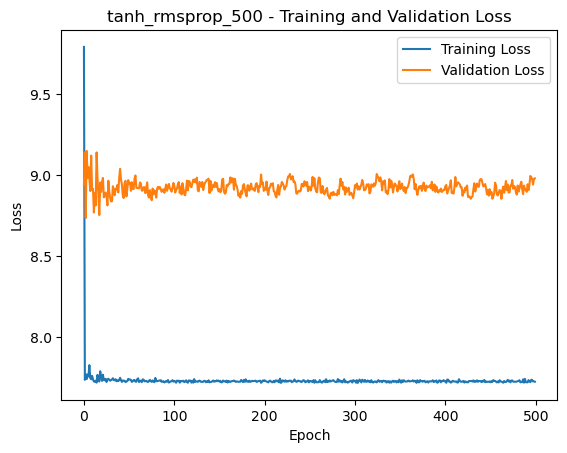

Epoch 1/1000


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 10.7456 - val_loss: 9.0587
Epoch 2/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6279 - val_loss: 9.4988
Epoch 3/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8161 - val_loss: 8.7341
Epoch 4/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4594 - val_loss: 9.1759
Epoch 5/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4743 - val_loss: 9.0538
Epoch 6/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5486 - val_loss: 8.9513
Epoch 7/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.1865 - val_loss: 9.2311
Epoch 8/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8723 - val_loss: 8.7837
Epoch 9/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9707 - val_loss: 8.8204
Epoch 10/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.2270 - val_loss: 9.3031
Epoch 11/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7614 - val_loss: 8.8623
Epoch 12/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.

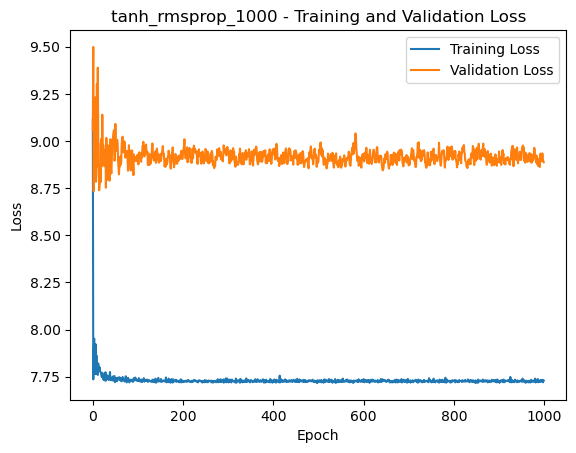

Epoch 1/10


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 14.2178 - val_loss: 10.8691
Epoch 2/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 10.9186 - val_loss: 9.1327
Epoch 3/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.3245 - val_loss: 8.7469
Epoch 4/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8151 - val_loss: 8.7614
Epoch 5/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4394 - val_loss: 8.8362
Epoch 6/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4032 - val_loss: 8.8764
Epoch 7/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6023 - val_loss: 8.9180
Epoch 8/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9239 - val_loss: 8.9115
Epoch 9/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.1974 - val_loss: 8.9298
Epoch 10/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3785 - val_loss: 8.9181
sigmoid_adam_10=>Activation: sigmoid, Optimizer: adam, Epochs: 10, Test MSE: 6.155795574188232


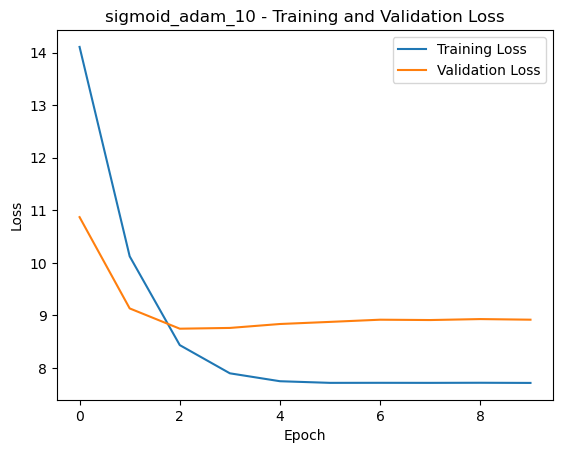

Epoch 1/25


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 31.7756 - val_loss: 21.0325
Epoch 2/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 22.9993 - val_loss: 15.5594
Epoch 3/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 15.3637 - val_loss: 12.6850
Epoch 4/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 13.0684 - val_loss: 11.1484
Epoch 5/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 10.4088 - val_loss: 10.3067
Epoch 6/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 10.2118 - val_loss: 9.7741
Epoch 7/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 10.0463 - val_loss: 9.4335
Epoch 8/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.9666 - val_loss: 9.2176
Epoch 9/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.0368 - val_loss: 9.0667
Epoch 10/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.4284 - val_loss: 8.9610
Epoch 11/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4976 - val_loss: 8.8835
Epoch 12/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.3946 - val_

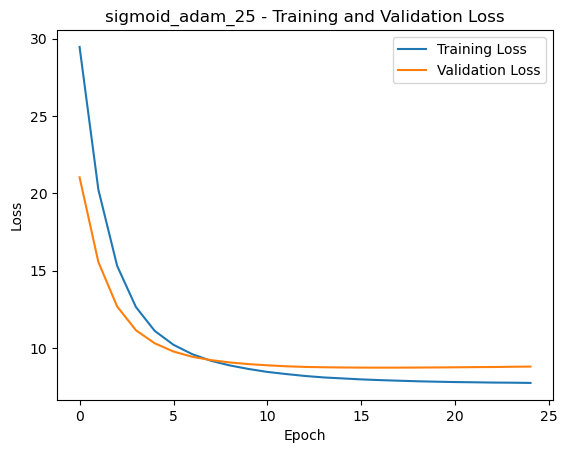

Epoch 1/50


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 17.7978 - val_loss: 11.7498
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 12.0810 - val_loss: 9.5198
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.9792 - val_loss: 8.8365
Epoch 4/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.1786 - val_loss: 8.7329
Epoch 5/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.2693 - val_loss: 8.7838
Epoch 6/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9134 - val_loss: 8.8658
Epoch 7/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3993 - val_loss: 8.9065
Epoch 8/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6924 - val_loss: 8.9259
Epoch 9/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5678 - val_loss: 8.9423
Epoch 10/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.4491 - val_loss: 8.9277
Epoch 11/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9610 - val_loss: 8.9135
Epoch 12/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5197 - val_loss: 8.9

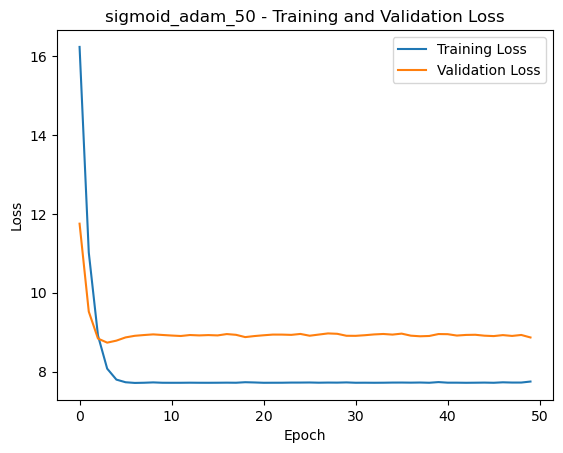

Epoch 1/100


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 25.1372 - val_loss: 16.4274
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 19.5763 - val_loss: 12.9097
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 12.5864 - val_loss: 11.0292
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 11.1753 - val_loss: 9.9135
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.8423 - val_loss: 9.2760
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.4172 - val_loss: 8.9371
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.5250 - val_loss: 8.7897
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.7939 - val_loss: 8.7386
Epoch 9/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.4527 - val_loss: 8.7339
Epoch 10/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.2189 - val_loss: 8.7486
Epoch 11/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.1646 - val_loss: 8.7806
Epoch 12/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3844 

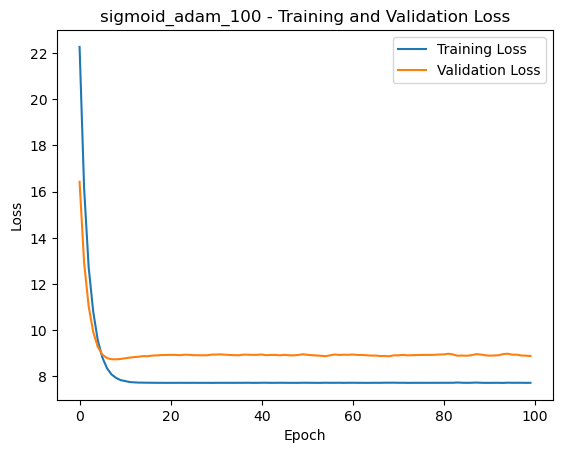

Epoch 1/500


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 17.9117 - val_loss: 12.4930
Epoch 2/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 11.6699 - val_loss: 9.8866
Epoch 3/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.1928 - val_loss: 8.9524
Epoch 4/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.2741 - val_loss: 8.7336
Epoch 5/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.1199 - val_loss: 8.7789
Epoch 6/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8340 - val_loss: 8.8522
Epoch 7/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.3592 - val_loss: 8.9144
Epoch 8/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5874 - val_loss: 8.9200
Epoch 9/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6907 - val_loss: 8.9042
Epoch 10/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7139 - val_loss: 8.9316
Epoch 11/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5165 - val_loss: 8.8979
Epoch 12/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0480 - va

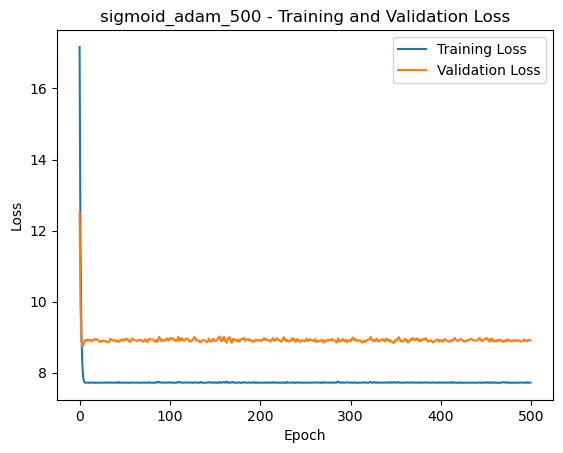

Epoch 1/1000


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 32.1510 - val_loss: 21.5886
Epoch 2/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 23.0273 - val_loss: 16.9978
Epoch 3/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 17.3193 - val_loss: 14.5260
Epoch 4/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 16.1779 - val_loss: 13.0317
Epoch 5/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 13.5350 - val_loss: 12.0665
Epoch 6/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 12.8083 - val_loss: 11.3827
Epoch 7/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 12.4711 - val_loss: 10.8751
Epoch 8/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 11.0682 - val_loss: 10.4690
Epoch 9/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 10.9364 - val_loss: 10.1505
Epoch 10/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 10.2816 - val_loss: 9.8679
Epoch 11/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.8411 - val_loss: 9.6395
Epoch 12/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6

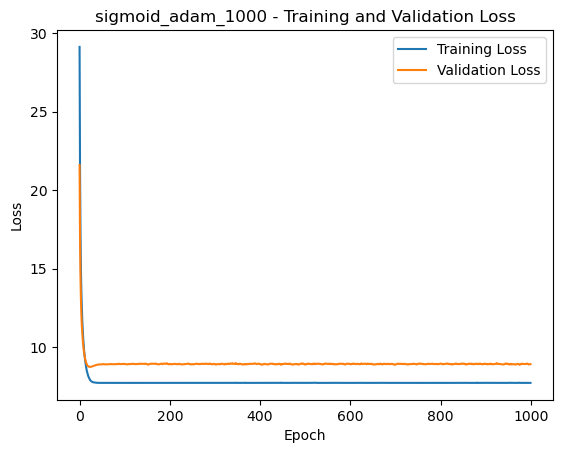

Epoch 1/10


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 13.1910 - val_loss: 8.8877
Epoch 2/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8269 - val_loss: 8.8757
Epoch 3/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9196 - val_loss: 9.6370
Epoch 4/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.6225 - val_loss: 9.0022
Epoch 5/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3266 - val_loss: 8.9228
Epoch 6/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.2478 - val_loss: 9.0659
Epoch 7/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4192 - val_loss: 9.7969
Epoch 8/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8487 - val_loss: 9.0549
Epoch 9/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3791 - val_loss: 8.9767
Epoch 10/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8729 - val_loss: 8.8508
sigmoid_sgd_10=>Activation: sigmoid, Optimizer: sgd, Epochs: 10, Test MSE: 6.1427435874938965


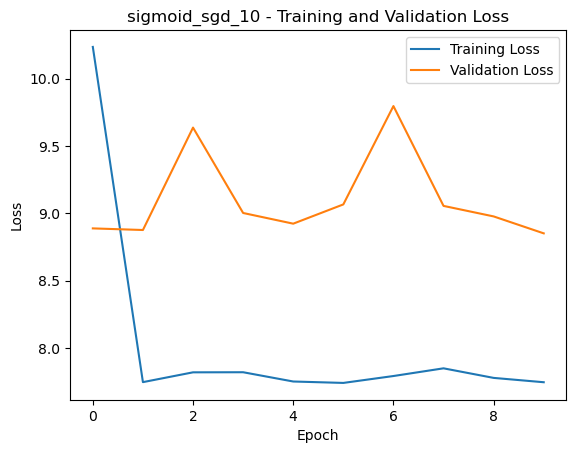

Epoch 1/25


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 14.7271 - val_loss: 8.8917
Epoch 2/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0857 - val_loss: 9.1809
Epoch 3/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0078 - val_loss: 9.5106
Epoch 4/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0733 - val_loss: 9.0108
Epoch 5/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5267 - val_loss: 8.9059
Epoch 6/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8915 - val_loss: 9.1025
Epoch 7/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9902 - val_loss: 8.7370
Epoch 8/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4685 - val_loss: 8.8815
Epoch 9/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5911 - val_loss: 8.7824
Epoch 10/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.2966 - val_loss: 9.1240
Epoch 11/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7275 - val_loss: 8.7505
Epoch 12/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9644 - val_loss: 8.851

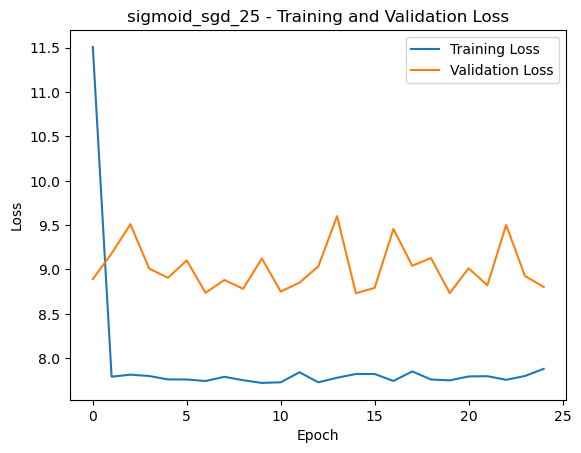

Epoch 1/50


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 15.6666 - val_loss: 9.0780
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3645 - val_loss: 9.1208
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.7126 - val_loss: 8.8036
Epoch 4/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.2039 - val_loss: 8.9251
Epoch 5/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5300 - val_loss: 8.8311
Epoch 6/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6446 - val_loss: 8.7711
Epoch 7/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7703 - val_loss: 9.0774
Epoch 8/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6574 - val_loss: 8.7379
Epoch 9/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.5500 - val_loss: 8.7803
Epoch 10/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5304 - val_loss: 9.0514
Epoch 11/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0753 - val_loss: 8.9463
Epoch 12/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4128 - val_loss: 9.161

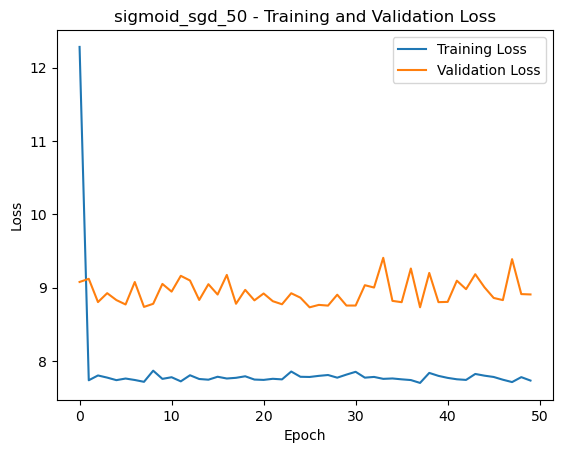

Epoch 1/100


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 15.0768 - val_loss: 8.8879
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 6.4132 - val_loss: 9.3345
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8971 - val_loss: 8.8496
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6523 - val_loss: 8.9188
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4076 - val_loss: 8.7748
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8504 - val_loss: 8.7975
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5196 - val_loss: 8.8925
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.0740 - val_loss: 8.9953
Epoch 9/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0484 - val_loss: 8.9223
Epoch 10/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5088 - val_loss: 8.9006
Epoch 11/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0788 - val_loss: 8.9489
Epoch 12/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6201 - val_

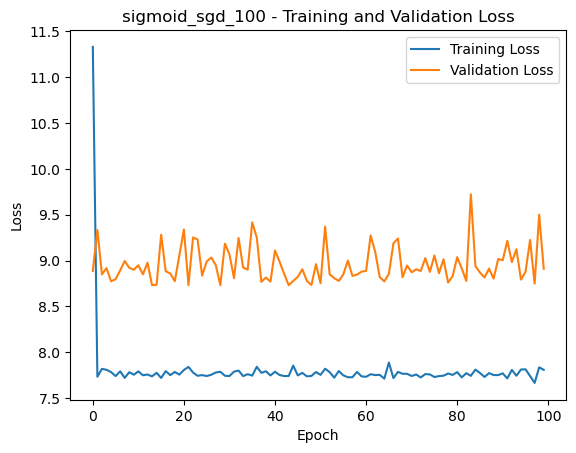

Epoch 1/500
 1/11 ━━━━━━━━━━━━━━━━━━━━ 1s 155ms/step - loss: 15.5064

/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 13.6106 - val_loss: 8.7749
Epoch 2/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9864 - val_loss: 8.7622
Epoch 3/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.4453 - val_loss: 8.8087
Epoch 4/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3745 - val_loss: 9.3317
Epoch 5/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4985 - val_loss: 8.9603
Epoch 6/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4713 - val_loss: 8.9260
Epoch 7/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0927 - val_loss: 8.7822
Epoch 8/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7369 - val_loss: 8.8995
Epoch 9/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.3153 - val_loss: 8.8656
Epoch 10/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.1410 - val_loss: 8.7452
Epoch 11/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.1873 - val_loss: 9.0166
Epoch 12/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9719 - val_

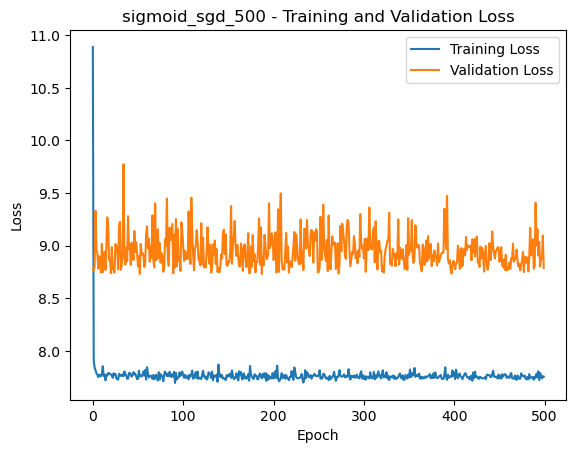

Epoch 1/1000


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 17.0298 - val_loss: 8.7722
Epoch 2/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7991 - val_loss: 8.9369
Epoch 3/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9997 - val_loss: 9.4923
Epoch 4/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8629 - val_loss: 8.7759
Epoch 5/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6896 - val_loss: 8.8873
Epoch 6/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.2180 - val_loss: 8.7391
Epoch 7/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3641 - val_loss: 9.2535
Epoch 8/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.1097 - val_loss: 9.4153
Epoch 9/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7070 - val_loss: 9.2050
Epoch 10/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5302 - val_loss: 9.2342
Epoch 11/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5359 - val_loss: 9.3915
Epoch 12/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.

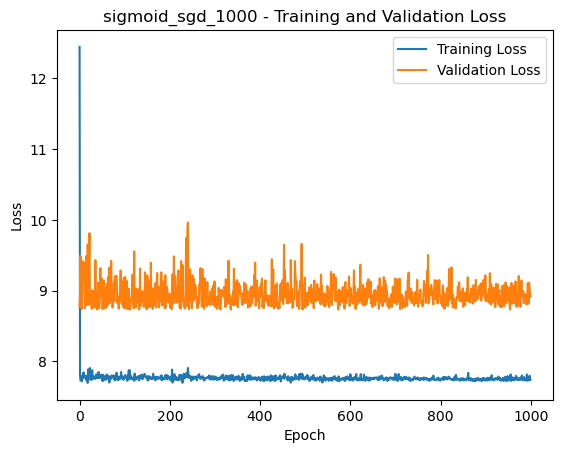

Epoch 1/10


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 24.0280 - val_loss: 13.9099
Epoch 2/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 13.6365 - val_loss: 10.8574
Epoch 3/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 10.8235 - val_loss: 9.6102
Epoch 4/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.5848 - val_loss: 9.0345
Epoch 5/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.0272 - val_loss: 8.7869
Epoch 6/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.6642 - val_loss: 8.7323
Epoch 7/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0159 - val_loss: 8.7766
Epoch 8/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.1515 - val_loss: 8.8169
Epoch 9/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6196 - val_loss: 8.8740
Epoch 10/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4712 - val_loss: 8.8924
sigmoid_rmsprop_10=>Activation: sigmoid, Optimizer: rmsprop, Epochs: 10, Test MSE: 6.14941930770874


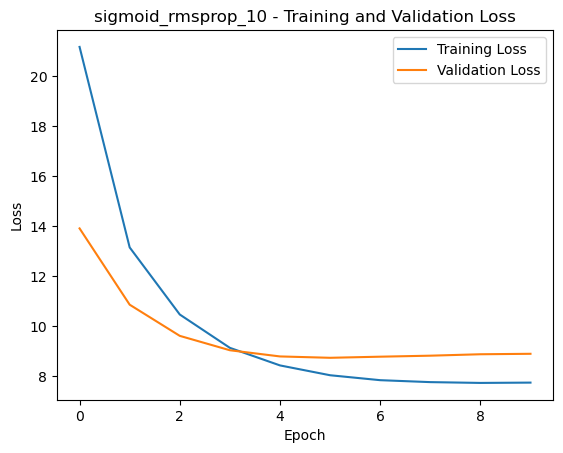

Epoch 1/25


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 25.4249 - val_loss: 14.1277
Epoch 2/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 13.9313 - val_loss: 10.9318
Epoch 3/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 10.4050 - val_loss: 9.6167
Epoch 4/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.9321 - val_loss: 9.0544
Epoch 5/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.8958 - val_loss: 8.8152
Epoch 6/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9076 - val_loss: 8.7327
Epoch 7/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.0634 - val_loss: 8.7643
Epoch 8/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0133 - val_loss: 8.8030
Epoch 9/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6958 - val_loss: 8.8755
Epoch 10/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3659 - val_loss: 8.8843
Epoch 11/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.1359 - val_loss: 8.8805
Epoch 12/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8930 - val_loss: 8

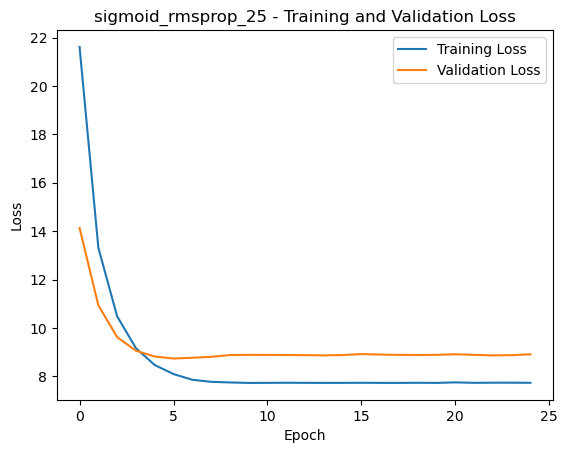

Epoch 1/50


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 15.8431 - val_loss: 9.6614
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 9.3726 - val_loss: 8.8225
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0550 - val_loss: 8.7322
Epoch 4/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7033 - val_loss: 8.8490
Epoch 5/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4989 - val_loss: 8.8967
Epoch 6/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4639 - val_loss: 8.9646
Epoch 7/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4818 - val_loss: 8.9714
Epoch 8/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5371 - val_loss: 8.9164
Epoch 9/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.2106 - val_loss: 8.9549
Epoch 10/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8162 - val_loss: 8.9374
Epoch 11/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0289 - val_loss: 8.9532
Epoch 12/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4050 - val_loss: 8.962

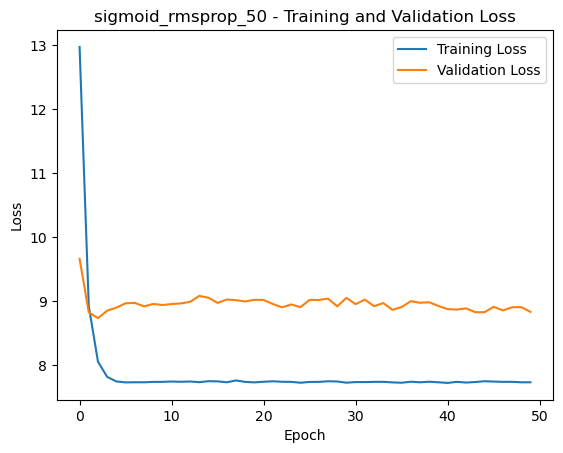

Epoch 1/100


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 32.8177 - val_loss: 19.0434
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 19.8197 - val_loss: 14.7346
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 15.2234 - val_loss: 12.4846
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 12.8751 - val_loss: 11.1161
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 12.3034 - val_loss: 10.2936
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 10.2310 - val_loss: 9.7240
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.2449 - val_loss: 9.3058
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.3944 - val_loss: 9.0699
Epoch 9/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0740 - val_loss: 8.8974
Epoch 10/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.1884 - val_loss: 8.8049
Epoch 11/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.1283 - val_loss: 8.7523
Epoch 12/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 8.2

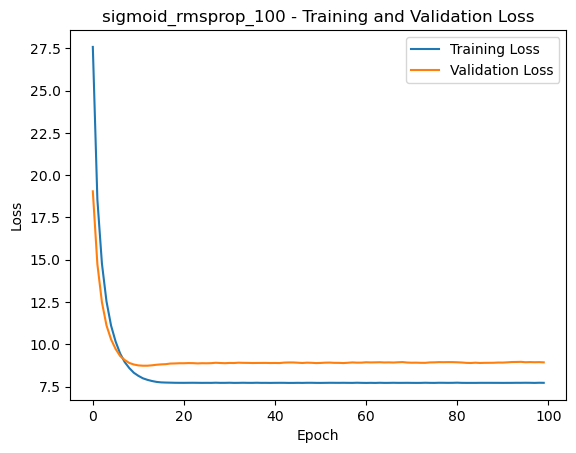

Epoch 1/500


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 14.2177 - val_loss: 9.9152
Epoch 2/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.8535 - val_loss: 8.8975
Epoch 3/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9966 - val_loss: 8.7348
Epoch 4/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9613 - val_loss: 8.8541
Epoch 5/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7403 - val_loss: 8.8053
Epoch 6/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8682 - val_loss: 8.8740
Epoch 7/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.3239 - val_loss: 8.8130
Epoch 8/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6034 - val_loss: 8.9629
Epoch 9/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4818 - val_loss: 8.9081
Epoch 10/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5193 - val_loss: 8.8990
Epoch 11/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4852 - val_loss: 8.9631
Epoch 12/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5765 - val_

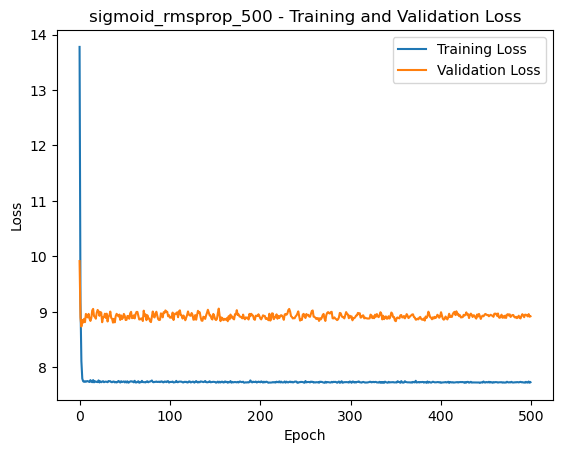

Epoch 1/1000


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 22.6330 - val_loss: 14.1209
Epoch 2/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 14.8743 - val_loss: 11.1269
Epoch 3/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 11.1029 - val_loss: 9.7515
Epoch 4/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.7367 - val_loss: 9.0865
Epoch 5/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 9.0527 - val_loss: 8.7826
Epoch 6/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9134 - val_loss: 8.7328
Epoch 7/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.0515 - val_loss: 8.7807
Epoch 8/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5311 - val_loss: 8.8248
Epoch 9/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.6283 - val_loss: 8.9024
Epoch 10/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7455 - val_loss: 8.9038
Epoch 11/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9816 - val_loss: 8.9640
Epoch 12/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss

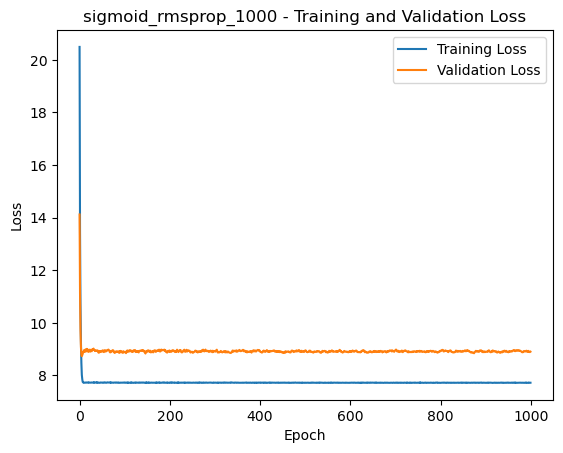

In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split  # <-- Add this import
from tensorflow.keras.models import Sequential  # <-- Add this import
from tensorflow.keras.layers import Dense  # <-- Add this import

# Assuming you have run the data preparation code and have `data_cleaned`
# Use the cleaned DataFrame for splitting so the model doesn't get NaNs/infs
train_df, temp_df = train_test_split(data_cleaned, test_size=0.3, random_state=42) # 70% train, 30% temp
val_df, test_df = train_test_split(temp_df, test_size=(1/3), random_state=42) # ~10% test, ~20% validation
 # Define features (X) and target (y)

x_train = train_df[feature_cols]
y_train = train_df[target_col]
x_val = val_df[feature_cols]
y_val = val_df[target_col]
x_test = test_df[feature_cols]
y_test = test_df[target_col]

# Quick sanity checks: ensure there are no NaNs or infs in inputs/targets
def has_invalid(x):
    return np.isnan(x).any() or np.isinf(x).any()

for name, arr in [('x_train', x_train.values), ('y_train', y_train.values), ('x_val', x_val.values), ('y_val', y_val.values), ('x_test', x_test.values), ('y_test', y_test.values)]:
    if has_invalid(arr):
        raise ValueError(f"Invalid values found in {name} (NaN or Inf). Check data_cleaned and preprocessing.")




# activation_functions = ['relu', 'elu', 'selu', 'tanh', 'sigmoid']
activation_functions = ['tanh', 'sigmoid']
# activation_functions = ['tanh']
optimizers = ['adam', 'sgd', 'rmsprop']
# optimizers = ['rmsprop']
# epochs = [15, 50, 100]
epochs = [10, 25, 50, 100, 500, 1000]
models = {}
for activation in activation_functions:
    for optimizer in optimizers:
        for epoch in epochs:
            model_name = f"{activation}_{optimizer}_{epoch}"
            model = Sequential([
                Dense(256, activation=activation, input_shape=(x_train.shape[1],)),  # Input layer
                Dense(128, activation=activation),  # Hidden layer
                Dense(64, activation=activation),  # Hidden layer
                Dense(32, activation=activation),  # Hidden layer
                Dense(1)  # Output layer (regression)
            ])
            model.compile(optimizer=optimizer, loss='mean_squared_error')
            history = model.fit(
                x_train, y_train,
                epochs=epoch,
                validation_data=(x_val, y_val),
                verbose=1
            )
            mse = model.evaluate(x_test, y_test, verbose=0)
            print(f'{model_name}=>Activation: {activation}, Optimizer: {optimizer}, Epochs: {epoch}, Test MSE: {mse}')
            # Store the model and its performance
            # You can use a dictionary or a list to store the models and their performance
            # For example:
            # models[activation + '_' + optimizer + '_' + str(epoch)] = (model, mse)
            models[model_name] = (model, mse)

            # 6. Visualize Training History
            import matplotlib.pyplot as plt
            plt.plot(history.history['loss'], label='Training Loss')
            plt.plot(history.history['val_loss'], label='Validation Loss')
            plt.xlabel('Epoch')
            plt.ylabel('Loss')
            plt.title(f"{model_name} - Training and Validation Loss")
            plt.legend()
            plt.show()

In [3]:
import numpy as np

if not models:
    print('No models found in `models`. Did the training cell run?')
else:
    def _safe_mse(item):
        """Return a numeric MSE for sorting or +inf when unavailable/NaN."""
        v = item[1]
        try:
            # expect v like (model, mse) or (model, mse, history)
            m = v[1]
            m = float(m)
        except Exception:
            m = float('nan')
        return m if not np.isnan(m) else float('inf')

    sorted_models = sorted(models.items(), key=_safe_mse)
    print("Models sorted by Test MSE (lowest to highest):")
    for name, val in sorted_models:
        try:
            mse_val = val[1]
            mse_str = f"{float(mse_val):.6g}"
        except Exception:
            mse_str = 'N/A'
        print(f"{name}: Test MSE = {mse_str}")

Models sorted by Test MSE (lowest to highest):
sigmoid_rmsprop_50: Test MSE = 6.14173
sigmoid_sgd_10: Test MSE = 6.14274
sigmoid_sgd_25: Test MSE = 6.14396
sigmoid_adam_25: Test MSE = 6.14401
sigmoid_adam_50: Test MSE = 6.1443
tanh_sgd_10: Test MSE = 6.14445
tanh_adam_25: Test MSE = 6.14598
tanh_adam_100: Test MSE = 6.14622
sigmoid_adam_100: Test MSE = 6.14664
tanh_rmsprop_50: Test MSE = 6.14701
sigmoid_sgd_500: Test MSE = 6.14747
tanh_rmsprop_1000: Test MSE = 6.14838
sigmoid_rmsprop_10: Test MSE = 6.14942
tanh_rmsprop_25: Test MSE = 6.14968
sigmoid_rmsprop_1000: Test MSE = 6.15234
sigmoid_rmsprop_25: Test MSE = 6.15298
sigmoid_sgd_50: Test MSE = 6.15311
sigmoid_adam_1000: Test MSE = 6.15332
sigmoid_adam_500: Test MSE = 6.15357
sigmoid_sgd_100: Test MSE = 6.15402
sigmoid_sgd_1000: Test MSE = 6.15456
tanh_sgd_50: Test MSE = 6.15484
tanh_adam_50: Test MSE = 6.15514
sigmoid_adam_10: Test MSE = 6.1558
sigmoid_rmsprop_500: Test MSE = 6.15614
tanh_adam_500: Test MSE = 6.15663
sigmoid_rmsprop

Model: tanh_adam_10, Test MSE: 6.196041107177734
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step


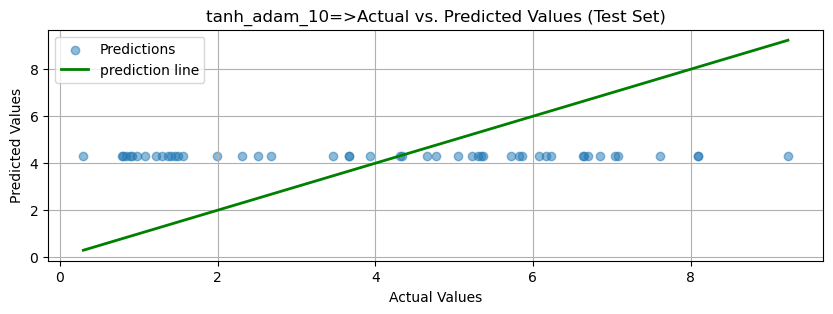

Model: tanh_adam_25, Test MSE: 6.145979404449463
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


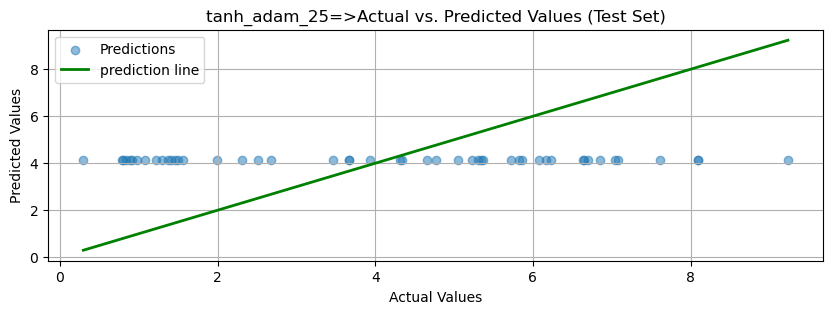

Model: tanh_adam_50, Test MSE: 6.155141353607178
1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/stepWARNING:tensorflow:6 out of the last 6 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x7aeb3c523880> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


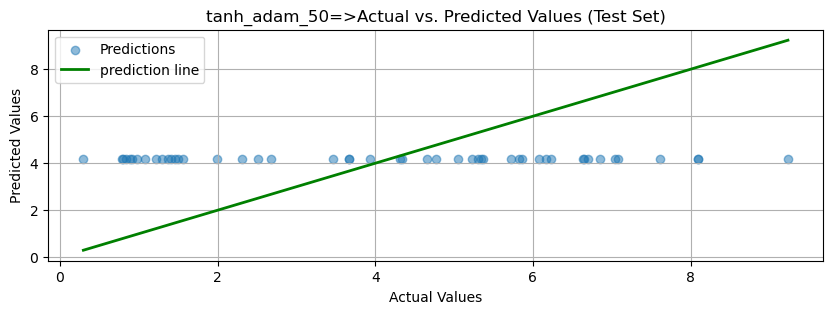

Model: tanh_adam_100, Test MSE: 6.146215438842773
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step


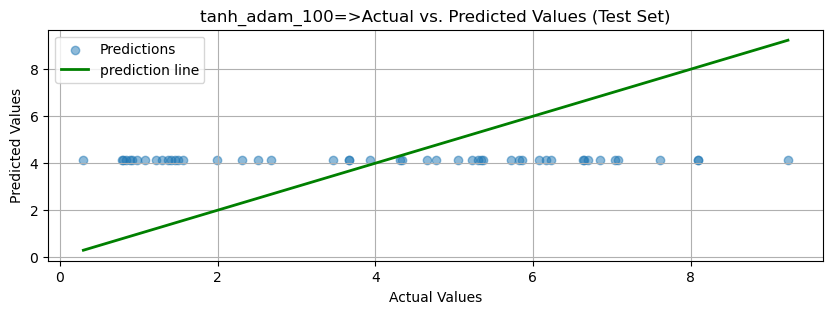

Model: tanh_adam_500, Test MSE: 6.156628131866455
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


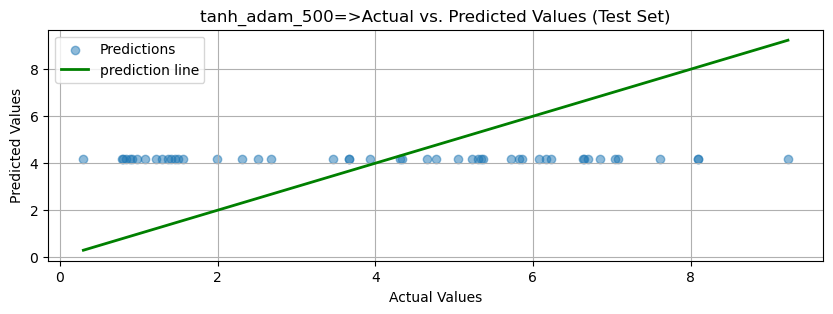

Model: tanh_adam_1000, Test MSE: 6.1735053062438965
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step 


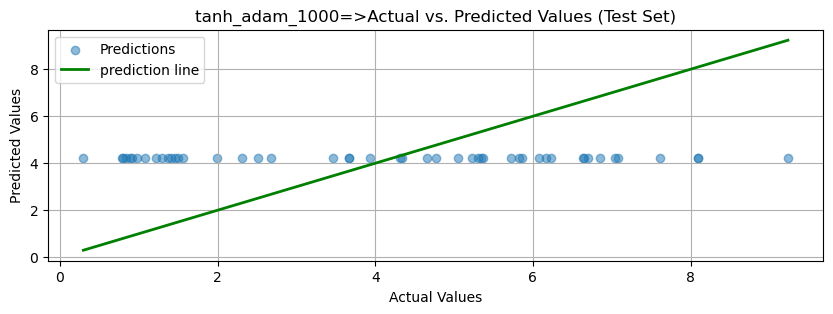

Model: tanh_sgd_10, Test MSE: 6.144450664520264
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step


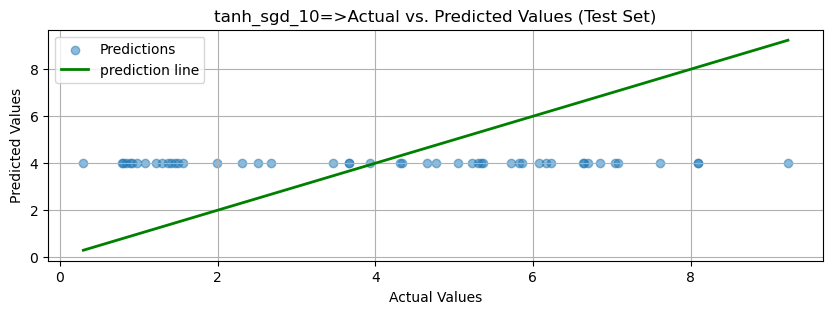

Model: tanh_sgd_25, Test MSE: 6.204868316650391
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step


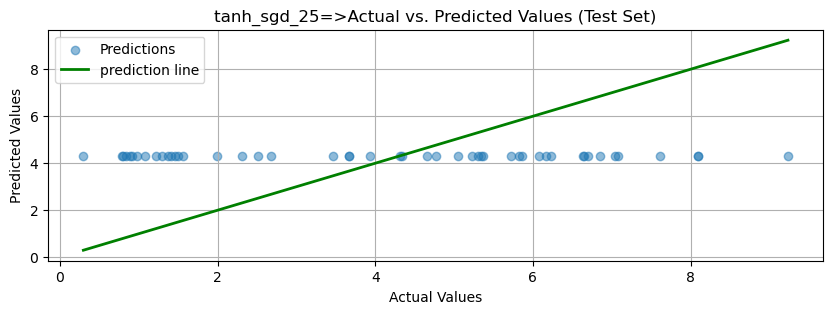

Model: tanh_sgd_50, Test MSE: 6.154842853546143
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


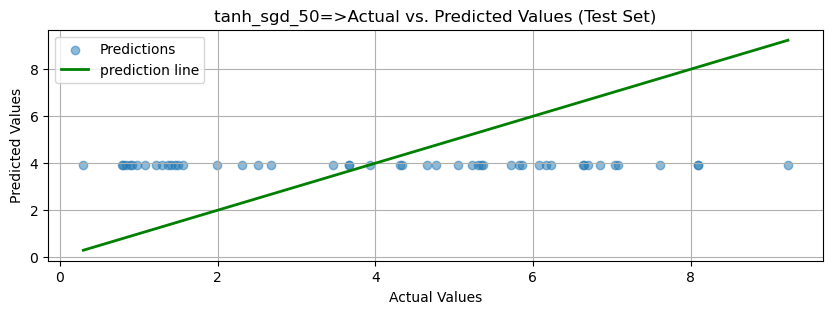

Model: tanh_sgd_100, Test MSE: 6.29152250289917
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


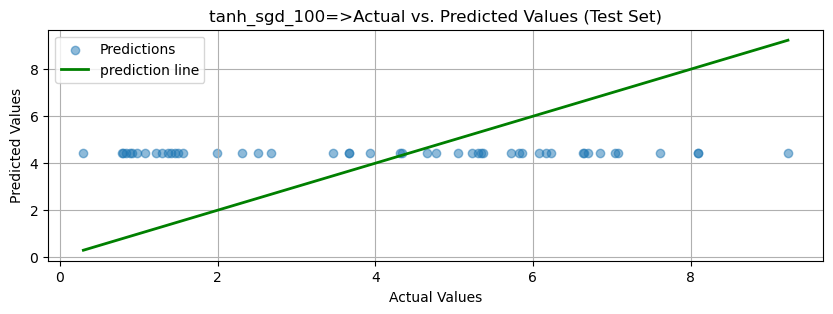

Model: tanh_sgd_500, Test MSE: 6.173741817474365
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


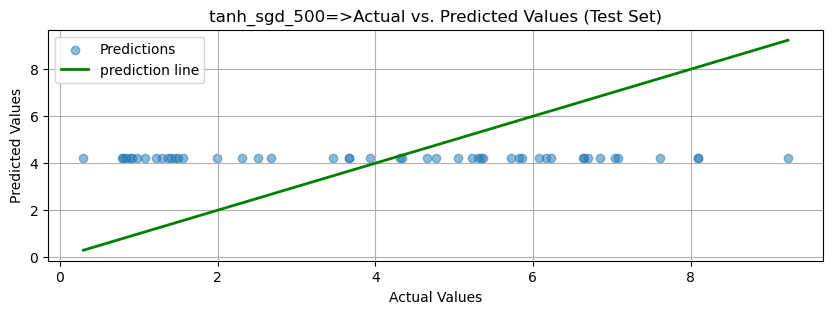

Model: tanh_sgd_1000, Test MSE: 6.183196544647217
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


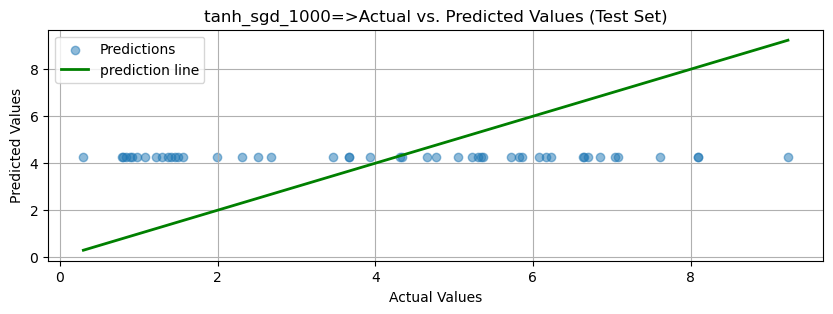

Model: tanh_rmsprop_10, Test MSE: 6.3345112800598145
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


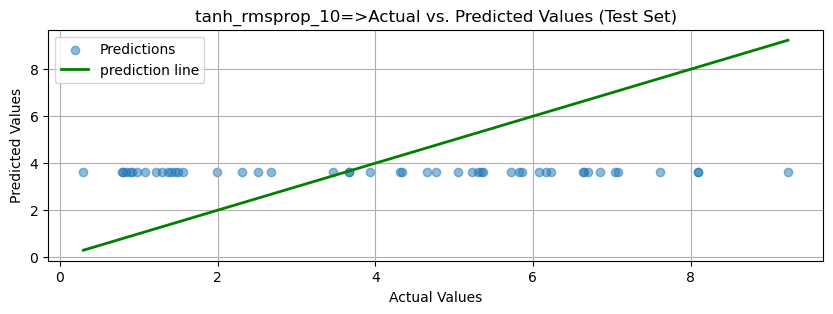

Model: tanh_rmsprop_25, Test MSE: 6.14967679977417
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


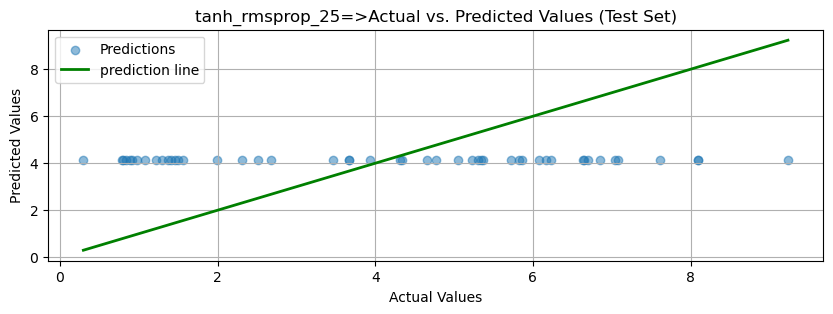

Model: tanh_rmsprop_50, Test MSE: 6.147008895874023
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


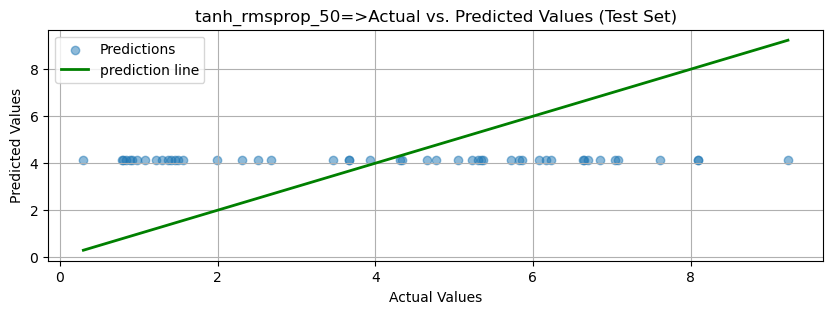

Model: tanh_rmsprop_100, Test MSE: 6.16388463973999
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


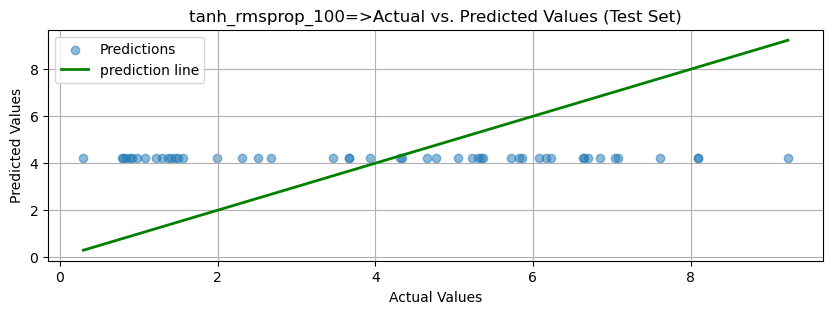

Model: tanh_rmsprop_500, Test MSE: 6.175833225250244
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


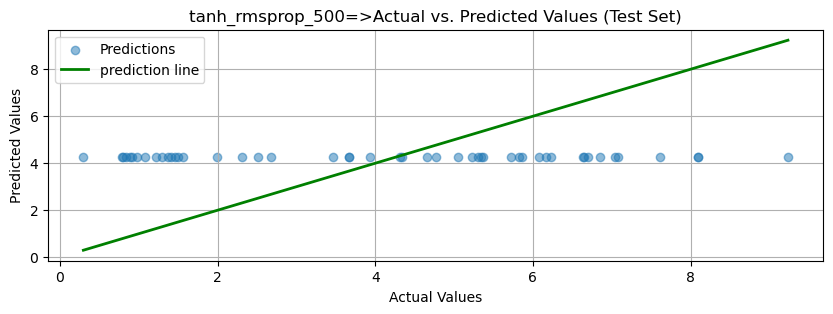

Model: tanh_rmsprop_1000, Test MSE: 6.148377895355225
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


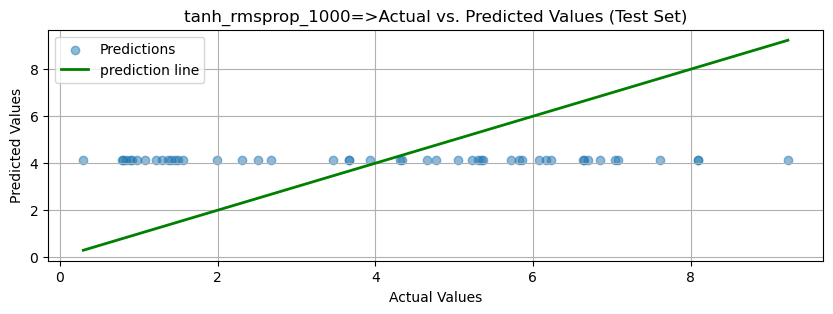

Model: sigmoid_adam_10, Test MSE: 6.155795574188232
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


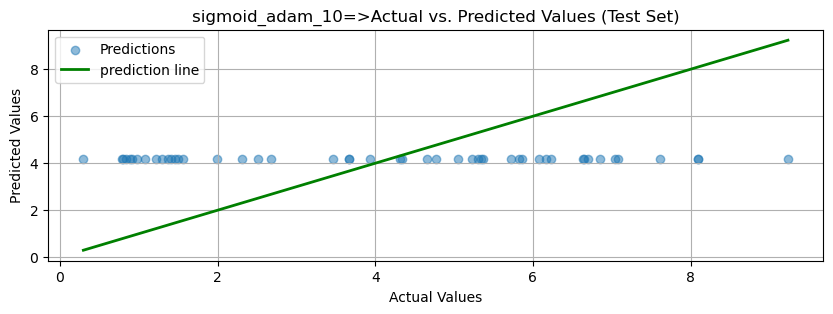

Model: sigmoid_adam_25, Test MSE: 6.144007205963135
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


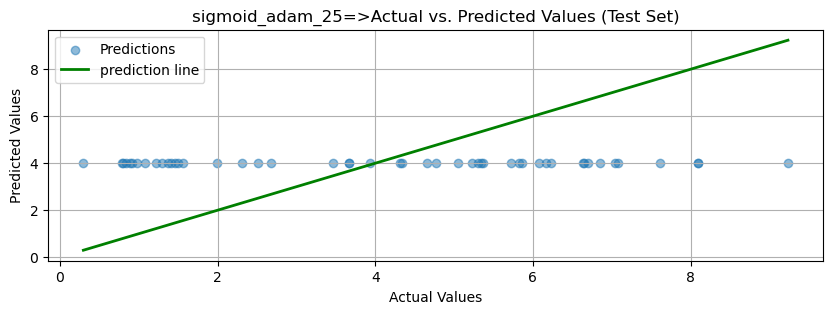

Model: sigmoid_adam_50, Test MSE: 6.144303798675537
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


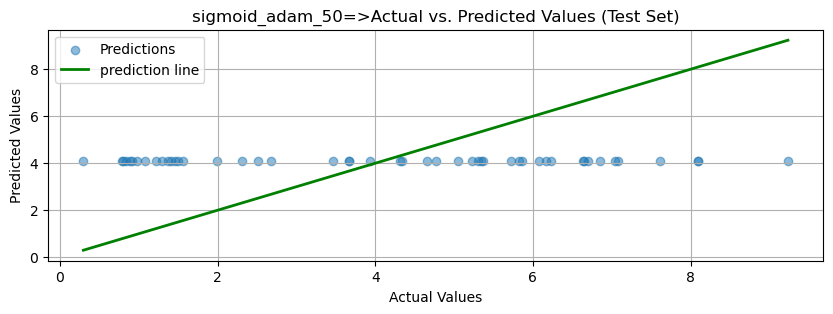

Model: sigmoid_adam_100, Test MSE: 6.146644592285156
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step


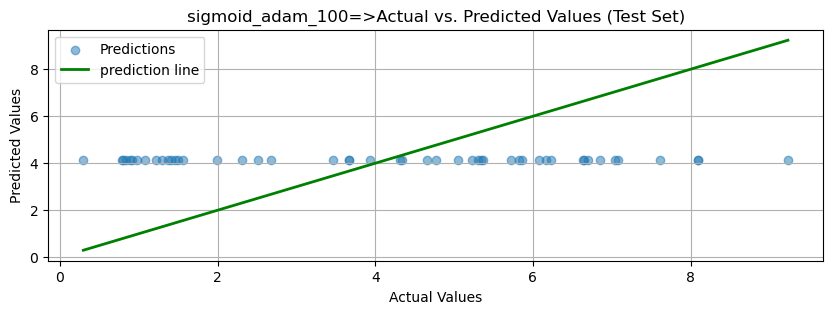

Model: sigmoid_adam_500, Test MSE: 6.153565883636475
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


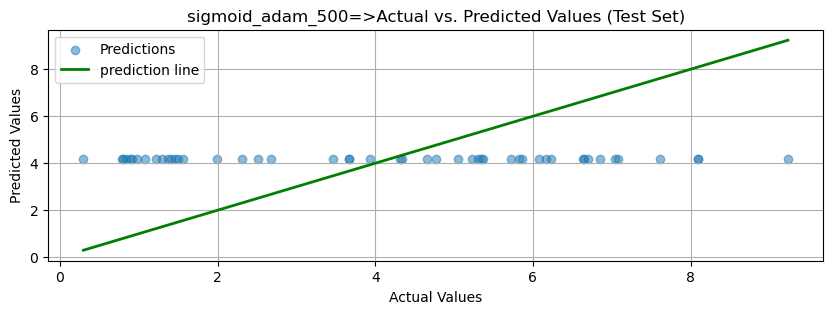

Model: sigmoid_adam_1000, Test MSE: 6.153316020965576
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


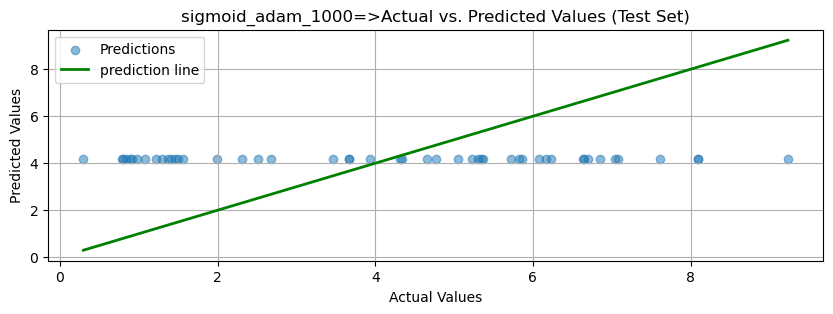

Model: sigmoid_sgd_10, Test MSE: 6.1427435874938965
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


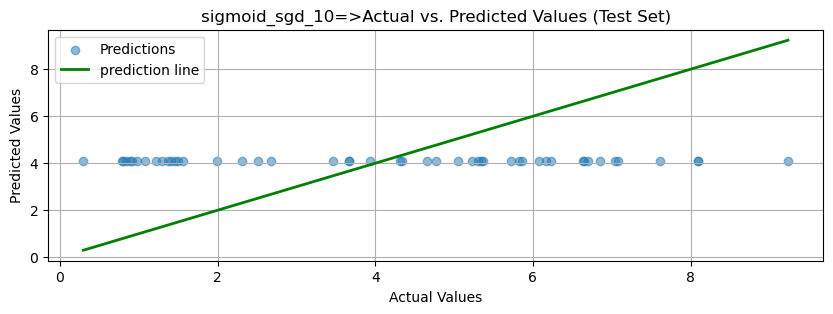

Model: sigmoid_sgd_25, Test MSE: 6.143955230712891
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step


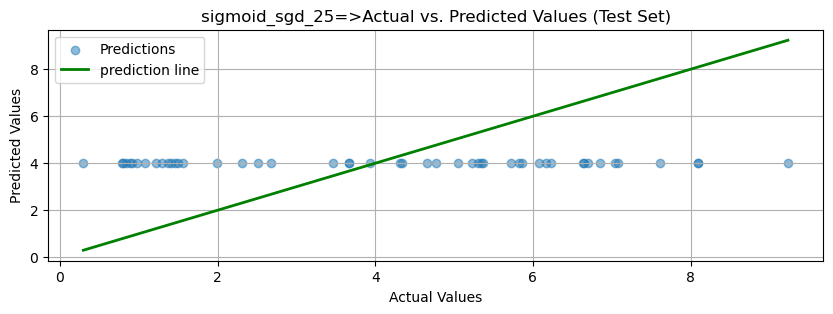

Model: sigmoid_sgd_50, Test MSE: 6.153108596801758
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


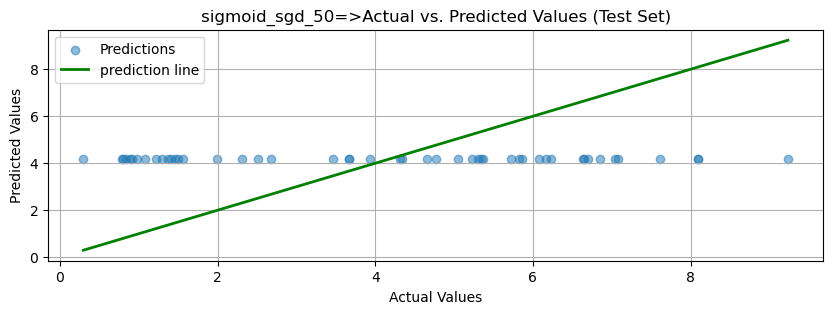

Model: sigmoid_sgd_100, Test MSE: 6.154016494750977
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


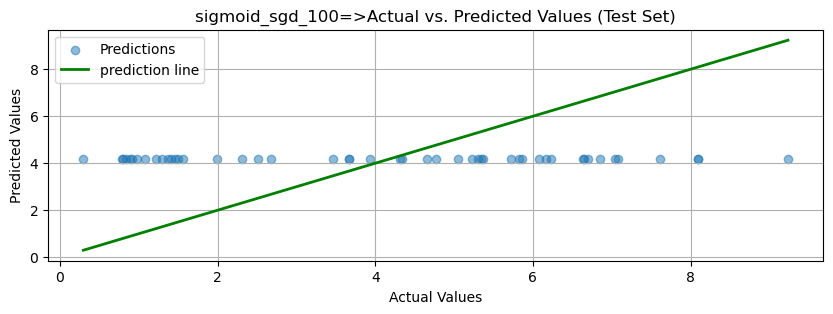

Model: sigmoid_sgd_500, Test MSE: 6.147472381591797
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


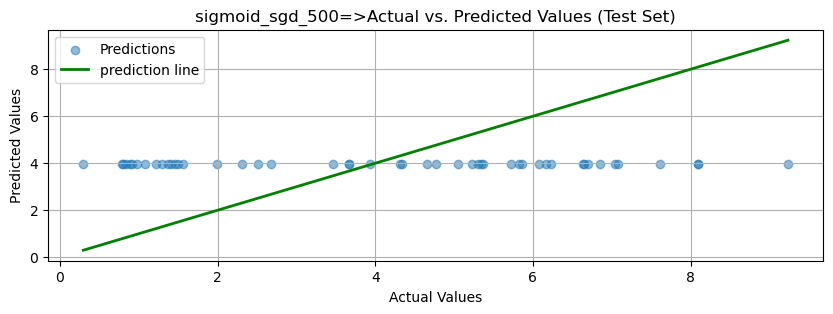

Model: sigmoid_sgd_1000, Test MSE: 6.154560089111328
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


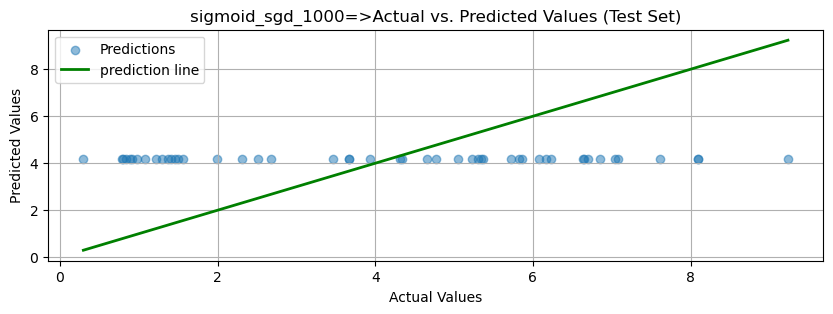

Model: sigmoid_rmsprop_10, Test MSE: 6.14941930770874
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


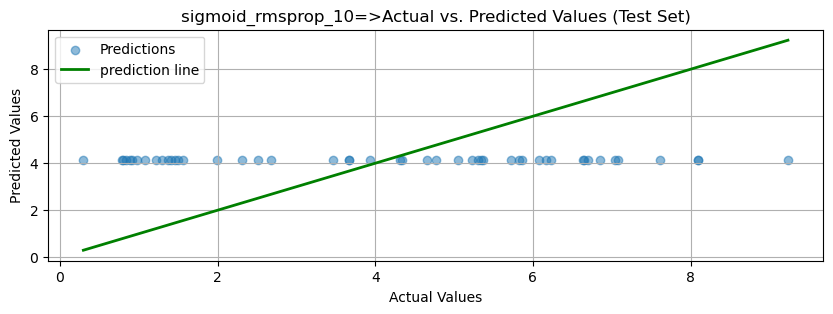

Model: sigmoid_rmsprop_25, Test MSE: 6.152977466583252
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


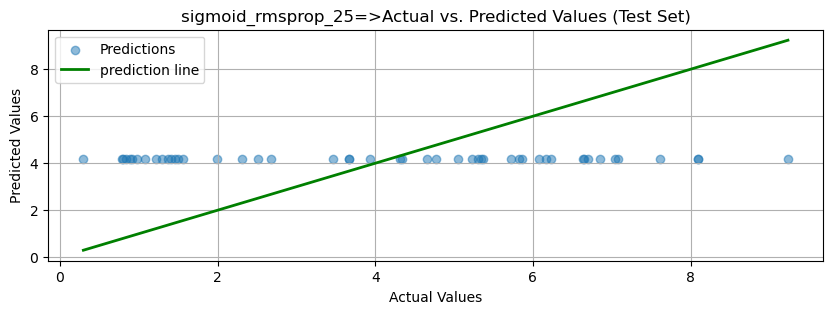

Model: sigmoid_rmsprop_50, Test MSE: 6.141725063323975
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step


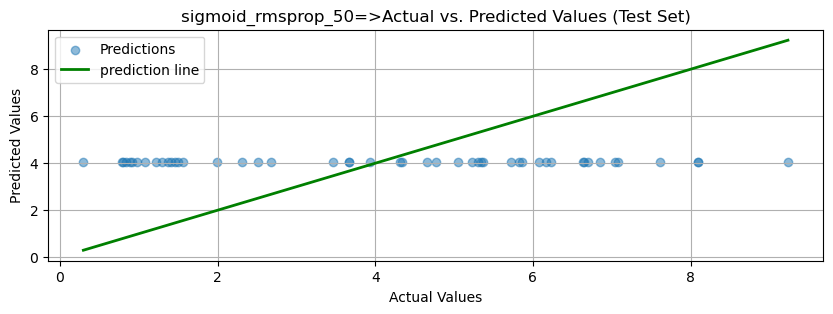

Model: sigmoid_rmsprop_100, Test MSE: 6.159847736358643
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


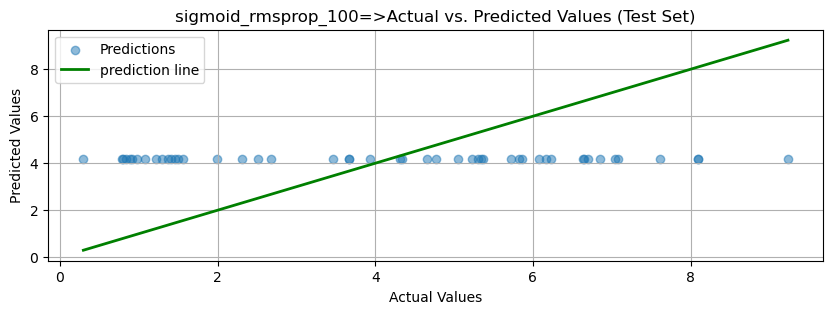

Model: sigmoid_rmsprop_500, Test MSE: 6.156137943267822
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step


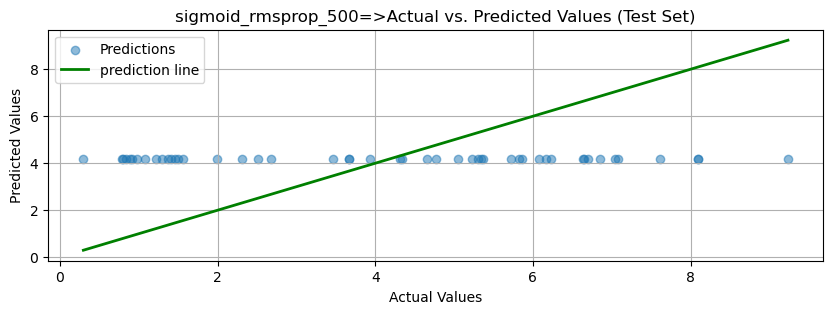

Model: sigmoid_rmsprop_1000, Test MSE: 6.15233850479126
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


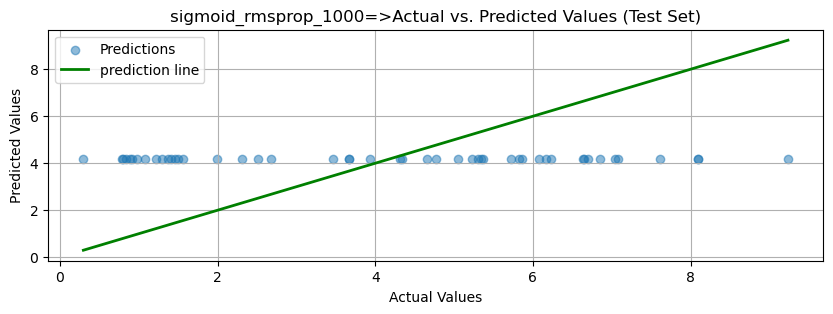

In [4]:
import matplotlib.pyplot as plt
import numpy as np

for model_name, (model, mse) in models.items():
    print(f"Model: {model_name}, Test MSE: {mse}")
    # Assuming you have already trained your model and have x_test
    # Now, let's make predictions on the test set
    if 'model' in locals() and 'x_test' in locals():
        y_pred_test = model.predict(x_test).ravel()  # Flatten to 1D

        # If y_test exists, we can compare predictions to actual values
        if 'y_test' in locals():
            # --- Test Set Visualization ---
            plt.figure(figsize=(10, 3))
            plt.scatter(y_test, y_pred_test, alpha=0.5, label='Predictions')

            # --- Highlight Negative Predictions ---
            negative_predictions_mask = y_pred_test < 0
            if np.any(negative_predictions_mask):
                plt.scatter(
                    y_test[negative_predictions_mask],
                    y_pred_test[negative_predictions_mask],
                    color='red',
                    label='Negative Predictions',
                    s=50,
                    marker='x'
                )
                print("Warning: The model predicted negative values. These might be physically unrealistic depending on what you are predicting.")

            # --- Plot the ideal prediction line ---
            min_val = min(np.min(y_test), np.min(y_test))
            max_val = max(np.max(y_test), np.max(y_test))
            p_min_val = min(np.min(y_pred_test), np.min(y_pred_test))
            p_max_val = max(np.max(y_pred_test), np.max(y_pred_test))
            plt.plot([min_val, max_val], [min_val, max_val], 'g-', lw=2, label='prediction line')

            plt.xlabel('Actual Values')
            plt.ylabel('Predicted Values')
            plt.title(f'{model_name}=>Actual vs. Predicted Values (Test Set)')
            plt.grid(True)
            plt.legend()
            plt.show()
    else:
        print("Please ensure that the model has been trained ('model' is defined) and you have test data ('x_test' is defined).")